## 0. Environment



In [ ]:
# Colab hardware information

import os
import platform
import psutil
import subprocess

print("=" * 60)
print("COLAB HARDWARE INFORMATION")
print("=" * 60)

# CPU
print("\n[CPU]")
print("Processor:", platform.processor())
print("Physical cores:", psutil.cpu_count(logical=False))
print("Logical cores:", psutil.cpu_count(logical=True))

# RAM
print("\n[RAM]")
total_ram_gb = psutil.virtual_memory().total / (1024 ** 3)
print(f"Total RAM: {total_ram_gb:.2f} GB")

# GPU
print("\n[GPU]")
try:
    result = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        capture_output=True,
        text=True,
        check=True
    )
    gpu_info = result.stdout.strip()
    if gpu_info:
        print(gpu_info)
    else:
        print("No GPU detected.")
except Exception:
    print("No NVIDIA GPU detected.")

# Platform
print("\n[SYSTEM]")
print("Python version:", platform.python_version())
print("Operating system:", platform.system())
print("Platform:", platform.platform())
print("Machine:", platform.machine())

print("=" * 60)

COLAB HARDWARE INFORMATION

[CPU]
Processor: x86_64
Physical cores: 1
Logical cores: 2

[RAM]
Total RAM: 12.67 GB

[GPU]
Tesla T4, 15360 MiB

[SYSTEM]
Python version: 3.13.15
Operating system: Linux
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Machine: x86_64


In [ ]:
%pip install -q openpyxl "flaml[automl]" h2o autogluon.tabular tpot optuna shap statsmodels lightgbm xgboost ngboost

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.3/266.3 MB 6.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.4/87.4 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 9.1 MB/s eta 0:00:0

In [ ]:
%pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 31.5 MB/s eta 0:00:00


In [ ]:
%pip uninstall -y tpot
%pip install -q --no-cache-dir "tpot==1.1.0"

Found existing installation: TPOT 0.12.2
Uninstalling TPOT-0.12.2:
  Successfully uninstalled TPOT-0.12.2
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.1/215.1 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.6/117.6 kB 192.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 143.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.2/86.2 kB 186.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 191.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.


In [ ]:
import tpot
import sklearn

print("TPOT:", tpot.__version__)
print("scikit-learn:", sklearn.__version__)

/usr/local/lib/python3.13/dist-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


TPOT: 1.1.0
scikit-learn: 1.6.1


In [ ]:
from pathlib import Path
import hashlib
import json
import os
import platform
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

import copy
import gc
import random

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.compose import ColumnTransformer
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch_geometric.nn import GCNConv, GATConv

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupKFold, PredefinedSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/AutoML")
except Exception:
    BASE_DIR = Path.cwd()

DATA_PATH = BASE_DIR / "Mixed_Dataset_v9.xlsx"
OUTPUT_DIR = BASE_DIR / "Round2_GroupedCV"
MODEL_DIR = OUTPUT_DIR / "models"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
AUDIT_DIR = OUTPUT_DIR / "audit"
for directory in [MODEL_DIR, PREDICTION_DIR, TABLE_DIR, FIGURE_DIR, AUDIT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
OUTER_FOLDS = 5
INNER_FOLDS = 3
SEARCH_BUDGET_SECONDS = 300
TARGET = "Total Cost"
FEATURES = ["Type", "Tributary Area", "Superimposed Load", "Formwork", "Concrete"]
CONFIG_COLUMNS = ["Type", "Tributary Area", "Superimposed Load"]
CATEGORICAL_FEATURES = ["Type"]
NUMERIC_FEATURES = [column for column in FEATURES if column not in CATEGORICAL_FEATURES]

# Set model names to [] to run only data/statistical audit cells.
AUTOML_MODELS_TO_RUN = ["FLAML", "AutoGluon", "H2O", "TPOT"]
BASELINES_TO_RUN = ["Random Forest", "XGBoost", "LightGBM", "NGBoost", "ANN", "LGB+NGBoost"]

print("Python:", platform.python_version())
print("Data:", DATA_PATH)
print("Output:", OUTPUT_DIR)
print("Search budget per outer fold:", SEARCH_BUDGET_SECONDS, "seconds")

Mounted at /content/drive
Python: 3.13.15
Data: /content/drive/MyDrive/AutoML/Mixed_Dataset_v9.xlsx
Output: /content/drive/MyDrive/AutoML/Round2_GroupedCV
Search budget per outer fold: 300 seconds


## 1. Data structure audit and immutable outer folds



In [ ]:
data = pd.read_excel(DATA_PATH, sheet_name="Sheet1").reset_index(drop=True)
missing = [column for column in FEATURES + [TARGET] if column not in data.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")
if data[FEATURES + [TARGET]].isna().any().any():
    raise ValueError("Missing values detected. Resolve them explicitly before modelling.")
if (data[TARGET] == 0).any():
    raise ValueError("Zero target values require an explicit MAPE policy.")

data.insert(0, "RowID", np.arange(len(data), dtype=int))
data["ConfigurationID"] = data.groupby(CONFIG_COLUMNS, sort=True, dropna=False).ngroup()
groups = data["ConfigurationID"].to_numpy()

outer_cv = GroupKFold(n_splits=OUTER_FOLDS)
outer_splits = list(outer_cv.split(data[FEATURES], data[TARGET], groups=groups))
data["OuterFold"] = -1
for fold, (_, test_idx) in enumerate(outer_splits, start=1):
    data.loc[test_idx, "OuterFold"] = fold

for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
    overlap = set(groups[train_idx]).intersection(groups[test_idx])
    assert not overlap, f"Configuration leakage in fold {fold}: {len(overlap)} groups"

group_sizes = data.groupby("ConfigurationID").size()
structure_audit = pd.DataFrame({
    "Item": [
        "Rows", "Configurations", "Minimum records per configuration",
        "Maximum records per configuration", "Year column present"
    ],
    "Value": [
        len(data), data["ConfigurationID"].nunique(), group_sizes.min(), group_sizes.max(),
        any("year" in str(column).lower() for column in data.columns)
    ],
})
display(structure_audit)
display(data.groupby("OuterFold").agg(Rows=("RowID", "size"), Configurations=("ConfigurationID", "nunique")))

data[["RowID", "ConfigurationID", "OuterFold"] + CONFIG_COLUMNS].to_csv(
    AUDIT_DIR / "outer_grouped_fold_assignments.csv", index=False, encoding="utf-8-sig"
)
structure_audit.to_csv(AUDIT_DIR / "dataset_structure_audit.csv", index=False, encoding="utf-8-sig")

,Item,Value
0,Rows,4477
1,Configurations,217
2,Minimum records per configuration,20
3,Maximum records per configuration,21
4,Year column present,False


,Rows,Configurations
OuterFold,,
1,888,43
2,888,43
3,907,44
4,907,44
5,887,43


In [ ]:
# Exact predictor duplicates with conflicting published costs are data-quality flags.
duplicate_conflicts = (
    data.groupby(FEATURES, dropna=False)[TARGET]
    .agg(RecordCount="size", UniqueTargetCount="nunique", TargetMin="min", TargetMax="max")
    .reset_index()
    .query("RecordCount > 1 and UniqueTargetCount > 1")
)
conflict_rows = data.merge(duplicate_conflicts[FEATURES], on=FEATURES, how="inner")
duplicate_conflicts.to_csv(AUDIT_DIR / "exact_predictor_conflict_groups.csv", index=False, encoding="utf-8-sig")
conflict_rows.to_csv(AUDIT_DIR / "exact_predictor_conflict_rows.csv", index=False, encoding="utf-8-sig")
print(f"Conflicting exact-predictor groups: {len(duplicate_conflicts)}")
print(f"Rows in those groups: {len(conflict_rows)}")
display(duplicate_conflicts.head(20))

Conflicting exact-predictor groups: 46
Rows in those groups: 92


,Type,Tributary Area,Superimposed Load,Formwork,Concrete,RecordCount,UniqueTargetCount,TargetMin,TargetMax
2720,5,225,40,8.552486,4.414414,2,2,14.05,14.85
2740,5,225,75,8.552486,4.414414,2,2,14.15,14.85
2760,5,225,125,8.552486,4.414414,2,2,14.35,15.10
2780,5,225,200,8.552486,4.414414,2,2,14.85,15.65
2800,5,300,40,8.552486,4.414414,2,2,14.15,14.95
2820,5,300,75,8.552486,4.414414,2,2,14.50,15.25
2840,5,300,125,8.552486,4.414414,2,2,15.15,15.90
2860,5,300,200,8.552486,4.414414,2,2,15.55,16.35
2880,5,400,40,8.552486,4.414414,2,2,14.10,14.90
2900,5,400,75,8.552486,4.414414,2,2,14.90,15.70


In [ ]:
configuration_columns = [
    "Type",
    "Tributary Area",
    "Superimposed Load",
]

configuration_sizes = (
    data
    .groupby(
        configuration_columns,
        dropna=False,
    )
    .size()
    .rename("NumberOfRecords")
)

total_records = len(data)
unique_configurations = len(configuration_sizes)

mean_records_per_configuration = (
    configuration_sizes.mean()
)

median_records_per_configuration = (
    configuration_sizes.median()
)

minimum_records_per_configuration = (
    configuration_sizes.min()
)

maximum_records_per_configuration = (
    configuration_sizes.max()
)

repeated_configurations = int(
    (configuration_sizes >= 2).sum()
)

repeated_configuration_percent = (
    repeated_configurations
    / unique_configurations
    * 100
)

records_in_repeated_configurations = int(
    configuration_sizes[
        configuration_sizes >= 2
    ].sum()
)

records_in_repeated_percent = (
    records_in_repeated_configurations
    / total_records
    * 100
)

dataset_structure = pd.DataFrame({
    "Item": [
        "Total records",
        "Unique configurations",
        "Mean records per configuration",
        "Median records per configuration",
        "Minimum records per configuration",
        "Maximum records per configuration",
        "Configurations with at least two records",
        "Percentage of repeated configurations",
        "Records belonging to repeated configurations",
        "Percentage of records in repeated configurations",
    ],
    "Value": [
        total_records,
        unique_configurations,
        mean_records_per_configuration,
        median_records_per_configuration,
        minimum_records_per_configuration,
        maximum_records_per_configuration,
        repeated_configurations,
        repeated_configuration_percent,
        records_in_repeated_configurations,
        records_in_repeated_percent,
    ],
})

display(dataset_structure)

dataset_structure.to_csv(
    TABLE_DIR / "Table1_dataset_structure.csv",
    index=False,
    encoding="utf-8-sig",
)

,Item,Value
0,Total records,4477.000000
1,Unique configurations,217.000000
2,Mean records per configuration,20.631336
3,Median records per configuration,21.000000
4,Minimum records per configuration,20.000000
5,Maximum records per configuration,21.000000
6,Configurations with at least two records,217.000000
7,Percentage of repeated configurations,100.000000
8,Records belonging to repeated configurations,4477.000000
9,Percentage of records in repeated configurations,100.000000


## 2. Shared helpers and output contract



In [ ]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MAPE_percent": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
    }


def make_group_fold_ids(group_values, n_splits=INNER_FOLDS):
    group_values = np.asarray(group_values)
    splitter = GroupKFold(n_splits=n_splits)
    fold_ids = np.full(len(group_values), -1, dtype=int)
    dummy_x = np.zeros((len(group_values), 1))
    for fold, (_, valid_idx) in enumerate(splitter.split(dummy_x, groups=group_values)):
        fold_ids[valid_idx] = fold
    assert (fold_ids >= 0).all()
    return fold_ids


def make_inner_splits(group_values, n_splits=INNER_FOLDS):
    group_values = np.asarray(group_values)
    splitter = GroupKFold(n_splits=n_splits)
    dummy_x = np.zeros((len(group_values), 1))
    return list(splitter.split(dummy_x, groups=group_values))


def prediction_frame(model_name, test_idx, fold, predictions):
    frame = data.loc[test_idx, ["RowID", "ConfigurationID", TARGET] + CONFIG_COLUMNS].copy()
    frame = frame.rename(columns={TARGET: "True_Cost"})
    frame["Predicted_Cost"] = np.asarray(predictions, dtype=float)
    frame["Fold"] = fold
    frame["Model"] = model_name
    return frame


def save_oof(model_name, frames):
    oof = pd.concat(frames, ignore_index=True).sort_values("RowID").reset_index(drop=True)
    required = {"RowID", "ConfigurationID", "Fold", "True_Cost", "Predicted_Cost", "Model"}
    if not required.issubset(oof.columns):
        raise ValueError(f"OOF output is missing: {required.difference(oof.columns)}")
    if oof["RowID"].duplicated().any() or len(oof) != len(data):
        raise ValueError(f"{model_name}: OOF predictions do not cover each row exactly once")
    path = PREDICTION_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_oof_predictions.csv"
    oof.to_csv(path, index=False, encoding="utf-8-sig")
    print(model_name, regression_metrics(oof["True_Cost"], oof["Predicted_Cost"]), path)
    return oof


def sklearn_preprocessor():
    return ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), NUMERIC_FEATURES),
    ])

## 3. Formula-reconstruction diagnostic



In [ ]:
diagnostic_specs = {
    "Structure_only_linear": (["Type", "Tributary Area", "Superimposed Load"], False),
    "Rates_only_linear": (["Formwork", "Concrete"], False),
    "Full_additive_linear": (FEATURES, False),
    "Full_interaction_ridge": (FEATURES, True),
}

diagnostic_rows = []
diagnostic_predictions = []
for name, (feature_columns, use_interactions) in diagnostic_specs.items():
    categorical = [column for column in feature_columns if column == "Type"]
    numeric = [column for column in feature_columns if column != "Type"]
    transformers = []
    if categorical:
        transformers.append(("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical))
    if numeric:
        transformers.append(("numeric", StandardScaler(), numeric))
    steps = [("preprocess", ColumnTransformer(transformers))]
    if use_interactions:
        steps.append(("interactions", PolynomialFeatures(degree=2, include_bias=False)))
        steps.append(("model", Ridge(alpha=1.0)))
    else:
        steps.append(("model", LinearRegression()))
    template = Pipeline(steps)

    oof = np.zeros(len(data), dtype=float)
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        model = clone(template)
        model.fit(data.loc[train_idx, feature_columns], data.loc[train_idx, TARGET])
        oof[test_idx] = model.predict(data.loc[test_idx, feature_columns])
    diagnostic_rows.append({"Diagnostic": name, **regression_metrics(data[TARGET], oof)})
    diagnostic_predictions.append(pd.DataFrame({
        "RowID": data["RowID"], "ConfigurationID": data["ConfigurationID"],
        "True_Cost": data[TARGET], "Predicted_Cost": oof, "Diagnostic": name,
    }))

diagnostic_table = pd.DataFrame(diagnostic_rows).sort_values("RMSE")
display(diagnostic_table)
diagnostic_table.to_csv(TABLE_DIR / "formula_reconstruction_diagnostic.csv", index=False, encoding="utf-8-sig")
pd.concat(diagnostic_predictions, ignore_index=True).to_csv(
    PREDICTION_DIR / "formula_reconstruction_diagnostic_predictions.csv", index=False, encoding="utf-8-sig"
)

,Diagnostic,RMSE,MAE,MAPE_percent
3,Full_interaction_ridge,0.691397,0.458291,2.848433
2,Full_additive_linear,1.515955,1.164817,7.286678
1,Rates_only_linear,3.227132,2.510741,15.889694
0,Structure_only_linear,3.485871,2.892063,19.198568


## 4. AutoML models: outer grouped CV and inner grouped search



In [ ]:
import os
from distributed import Client, LocalCluster

TPOT_WORKERS = min(2, os.cpu_count() or 1)

tpot_cluster = LocalCluster(
    n_workers=TPOT_WORKERS,
    threads_per_worker=1,
    processes=False,
    dashboard_address=None,
)

tpot_client = Client(tpot_cluster)
tpot_client.wait_for_workers(TPOT_WORKERS)

print(tpot_client)

INFO:distributed.http.proxy:To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at: inproc://172.28.0.12/10384/1
INFO:distributed.scheduler:  dashboard at:  http://172.28.0.12:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.worker:      Start worker at: inproc://172.28.0.12/10384/4
INFO:distributed.worker:         Listening to:          inproc172.28.0.12
INFO:distributed.worker:          Worker name:                          0
INFO:distributed.worker:         dashboard at:          172.28.0.12:33349
INFO:distributed.worker:Waiting to connect to: inproc://172.28.0.12/10384/1
INFO:distributed.worker:-------------------------------------------------
INFO:distributed.worker:              Threads:                          1
INFO:distributed.worker:               Memory:                   6.34 GiB
INFO:d

<Client: 'inproc://172.28.0.12/10384/1' processes=2 threads=2, memory=12.67 GiB>


In [ ]:
def run_flaml():
    from flaml import AutoML

    frames = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        model_path = MODEL_DIR / f"FLAML_fold_{fold}.joblib"
        automl = AutoML()
        automl.fit(
            X_train=data.loc[train_idx, FEATURES],
            y_train=data.loc[train_idx, TARGET],
            task="regression",
            metric="rmse",
            time_budget=SEARCH_BUDGET_SECONDS,
            eval_method="cv",
            split_type="group",
            groups=groups[train_idx],
            n_splits=INNER_FOLDS,
            seed=SEED + fold,
            n_jobs=-1,
            ensemble=False,
            verbose=0,
        )
        joblib.dump(automl, model_path)
        predictions = automl.predict(data.loc[test_idx, FEATURES])
        frames.append(prediction_frame("FLAML", test_idx, fold, predictions))
        pd.DataFrame([{
            "Fold": fold, "BestEstimator": automl.best_estimator,
            "BestConfig": json.dumps(automl.best_config, default=str),
        }]).to_csv(TABLE_DIR / f"FLAML_fold_{fold}_best_config.csv", index=False)
    return save_oof("FLAML", frames)


def run_autogluon():
    from autogluon.tabular import TabularPredictor

    frames = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        train_data = data.loc[train_idx, FEATURES + [TARGET]].copy()
        train_data["__inner_fold__"] = make_group_fold_ids(groups[train_idx])
        model_path = MODEL_DIR / f"AutoGluon_fold_{fold}"

        try:
            predictor = TabularPredictor(
                label=TARGET,
                problem_type="regression",
                eval_metric="root_mean_squared_error",
                path=str(model_path),
                learner_kwargs={"ignored_columns": ["__inner_fold__"]},
                verbosity=2,
            )
            predictor.fit(
                train_data=train_data,
                time_limit=SEARCH_BUDGET_SECONDS,
                presets="medium_quality",
                num_bag_sets=1,
                num_stack_levels=0,
                validation_structure={"group_on": "__inner_fold__"},
            )
        except TypeError:
            predictor = TabularPredictor(
                label=TARGET,
                problem_type="regression",
                eval_metric="root_mean_squared_error",
                path=str(model_path),
                groups="__inner_fold__",
                verbosity=2,
            )
            predictor.fit(
                train_data=train_data,
                time_limit=SEARCH_BUDGET_SECONDS,
                presets="medium_quality",
                num_bag_sets=1,
                num_stack_levels=0,
            )
        predictions = predictor.predict(data.loc[test_idx, FEATURES])
        frames.append(prediction_frame("AutoGluon", test_idx, fold, predictions))
    return save_oof("AutoGluon", frames)


def run_h2o():
    import h2o
    from h2o.automl import H2OAutoML

    h2o.init(max_mem_size="10G", strict_version_check=False)
    frames = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        train_data = data.loc[train_idx, FEATURES + [TARGET]].copy()
        train_data["__inner_fold__"] = make_group_fold_ids(groups[train_idx])
        test_data = data.loc[test_idx, FEATURES].copy()
        htrain = h2o.H2OFrame(train_data)
        htest = h2o.H2OFrame(test_data)
        htrain["Type"] = htrain["Type"].asfactor()
        htest["Type"] = htest["Type"].asfactor()
        aml = H2OAutoML(
            max_runtime_secs=SEARCH_BUDGET_SECONDS,
            seed=SEED + fold,
            sort_metric="RMSE",
            nfolds=INNER_FOLDS,
        )
        aml.train(
            x=FEATURES,
            y=TARGET,
            training_frame=htrain,
            fold_column="__inner_fold__",
        )
        predictions = aml.leader.predict(htest).as_data_frame().iloc[:, 0].to_numpy()
        frames.append(prediction_frame("H2O", test_idx, fold, predictions))
        h2o.save_model(aml.leader, path=str(MODEL_DIR / f"H2O_fold_{fold}"), force=True)
    return save_oof("H2O", frames)


def run_tpot():
    from tpot import TPOTRegressor

    frames = []
    encoded = pd.get_dummies(
        data[FEATURES],
        columns=["Type"],
        drop_first=False,
    )

    for fold, (train_idx, test_idx) in enumerate(
        outer_splits,
        start=1,
    ):
        print(f"\n===== TPOT: outer fold {fold}/{OUTER_FOLDS} =====")

        inner_fold_ids = make_group_fold_ids(groups[train_idx])
        inner_cv = PredefinedSplit(test_fold=inner_fold_ids)

        model = TPOTRegressor(
        search_space="linear",
        allow_inner_regressors=False,

        scorers=["neg_root_mean_squared_error"],
        scorers_weights=[1],
        cv=inner_cv,
        max_time_mins=SEARCH_BUDGET_SECONDS / 60,
        max_eval_time_mins=0.5,
        population_size=10,
        initial_population_size=10,
        memory="auto",
        random_state=SEED + fold,
        n_jobs=1,
        client=tpot_client,
        verbose=2,
)

        model.fit(encoded.iloc[train_idx], data.loc[train_idx, TARGET])
        joblib.dump(model.fitted_pipeline_, MODEL_DIR / f"TPOT_fold_{fold}.joblib")
        predictions = model.predict(encoded.iloc[test_idx])
        frames.append(prediction_frame("TPOT", test_idx, fold, predictions))
    return save_oof("TPOT", frames)

In [ ]:
AUTOML_MODELS_TO_RUN = ["TPOT"]
automl_outputs = {}
automl_outputs["TPOT"] = run_tpot()


Generation: : 0it [00:00, ?it/s]INFO:distributed.scheduler:Client Client-f7bde0ca-bd97-11f1-8c9e-0242ac1c000c requests to cancel 1 keys
INFO:distributed.scheduler:Scheduler cancels key eval_objective_list-99b88f8cf266a3c0110ad8e926f42c40.  Force=False
INFO:distributed.scheduler:Client Client-f7bde0ca-bd97-11f1-8c9e-0242ac1c000c requests to cancel 1 keys
INFO:distributed.scheduler:Scheduler cancels key eval_objective_list-70d7c72a4e7767452de61a4af55d1e48.  Force=False
Generation: : 1it [05:00, 300.65s/it]
Generation: : 0it [00:00, ?it/s]INFO:distributed.scheduler:Client Client-f7bde0ca-bd97-11f1-8c9e-0242ac1c000c requests to cancel 1 keys
INFO:distributed.scheduler:Scheduler cancels key eval_objective_list-1481d9854bbed3a27bf68b377dbbb2ba.  Force=False
INFO:distributed.scheduler:Client Client-f7bde0ca-bd97-11f1-8c9e-0242ac1c000c requests to cancel 1 keys
INFO:distributed.scheduler:Scheduler cancels key eval_objective_list-1254e065d42c4912a4e497e6958f3270.  Force=False
Generation: : 1it 

TPOT {'RMSE': 0.8971066945816089, 'MAE': 0.6319239694773797, 'MAPE_percent': 3.8887111963249574} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/TPOT_oof_predictions.csv


In [ ]:
automl_runners = {
    "FLAML": run_flaml,
}
automl_outputs = {}
for model_name in AUTOML_MODELS_TO_RUN:
    print(f"\n===== {model_name}: grouped outer CV =====")
    automl_outputs[model_name] = automl_runners[model_name]()


===== FLAML: grouped outer CV =====


INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
INFO:flaml.tune.searcher.blendsearch:No low-cost partial conf

FLAML {'RMSE': 0.49543958819509076, 'MAE': 0.3049312597359628, 'MAPE_percent': 1.8779739976575807} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/FLAML_oof_predictions.csv

===== AutoGluon: grouped outer CV =====


KeyError: 'AutoGluon'

In [ ]:
AUTOML_MODELS_TO_RUN = ["AutoGluon"]
automl_outputs = {}
automl_outputs["AutoGluon"] = run_autogluon()

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.15
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cu130
CUDA Version:       13.0
GPU Memory:         GPU 0: 14.56/14.56 GB
Total GPU Memory:   Free: 14.56 GB, Allocated: 0.00 GB, Total: 14.56 GB
GPU Count:          1
Memory Avail:       8.55 GB / 12.67 GB (67.4%)
Disk Space Avail:   1.83 GB / 15.00 GB (12.2%)
	We recommend a minimum available disk space of 10 GB, and large datasets may require more.
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 300s
AutoGluon will save models to "/content/drive/MyDrive/AutoML/Round2_GroupedCV/models/AutoGluon_fold_1"
Train Data Rows:    3589
Train Data Columns: 6
Label Column:       Total Cost
Problem Type:       regre

[1000]	valid_set's rmse: 0.900237


	-0.8981	 = Validation score   (-root_mean_squared_error)
	1.58s	 = Training   runtime
	0.16s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 297.91s of the 297.90s of remaining time.
	Fitting with cpus=1, gpus=0, mem=0.1/8.6 GB


[1000]	valid_set's rmse: 0.8486


	-0.8387	 = Validation score   (-root_mean_squared_error)
	1.42s	 = Training   runtime
	0.13s	 = Validation runtime
Fitting model: RandomForestMSE ... Training model for up to 296.18s of the 296.18s of remaining time.
	Fitting with cpus=2, gpus=0, mem=0.0/8.6 GB
	-0.8113	 = Validation score   (-root_mean_squared_error)
	2.63s	 = Training   runtime
	0.2s	 = Validation runtime
Fitting model: CatBoost ... Training model for up to 292.85s of the 292.85s of remaining time.
	Fitting with cpus=1, gpus=0
		`import catboost` failed. A quick tip is to install via `pip install autogluon.tabular[catboost]==1.6.3`.
Fitting model: ExtraTreesMSE ... Training model for up to 292.11s of the 292.10s of remaining time.
	Fitting with cpus=2, gpus=0, mem=0.0/8.5 GB
	-0.6906	 = Validation score   (-root_mean_squared_error)
	2.96s	 = Training   runtime
	0.22s	 = Validation runtime
Fitting model: NeuralNetFastAI ... Training model for up to 288.40s of the 288.40s of remaining time.
	Fitting with cpus=1, gpus=

...

[1000]	valid_set's rmse: 0.834212
[2000]	valid_set's rmse: 0.824039


	-0.8219	 = Validation score   (-root_mean_squared_error)
	1.25s	 = Training   runtime
	0.21s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 298.27s of the 298.27s of remaining time.
	Fitting with cpus=1, gpus=0, mem=0.1/9.9 GB
	-0.6771	 = Validation score   (-root_mean_squared_error)
	0.69s	 = Training   runtime
	0.03s	 = Validation runtime
Fitting model: RandomForestMSE ... Training model for up to 297.50s of the 297.49s of remaining time.
	Fitting with cpus=2, gpus=0, mem=0.0/9.9 GB
	-0.8963	 = Validation score   (-root_mean_squared_error)
	1.53s	 = Training   runtime
	0.12s	 = Validation runtime
Fitting model: CatBoost ... Training model for up to 295.56s of the 295.56s of remaining time.
	Fitting with cpus=1, gpus=0
		`import catboost` failed. A quick tip is to install via `pip install autogluon.tabular[catboost]==1.6.3`.
Fitting model: ExtraTreesMSE ... Training model for up to 295.13s of the 295.13s of remaining time.
	Fitting with cpus=2, gpus=0, mem

[1000]	valid_set's rmse: 0.769988
[2000]	valid_set's rmse: 0.741509
[3000]	valid_set's rmse: 0.736323
[4000]	valid_set's rmse: 0.736351


	-0.7347	 = Validation score   (-root_mean_squared_error)
	2.04s	 = Training   runtime
	0.43s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 297.13s of the 297.13s of remaining time.
	Fitting with cpus=1, gpus=0, mem=0.1/9.9 GB
	-0.6819	 = Validation score   (-root_mean_squared_error)
	0.89s	 = Training   runtime
	0.06s	 = Validation runtime
Fitting model: RandomForestMSE ... Training model for up to 296.07s of the 296.07s of remaining time.
	Fitting with cpus=2, gpus=0, mem=0.0/9.9 GB
	-1.0495	 = Validation score   (-root_mean_squared_error)
	1.72s	 = Training   runtime
	0.12s	 = Validation runtime
Fitting model: CatBoost ... Training model for up to 293.93s of the 293.93s of remaining time.
	Fitting with cpus=1, gpus=0
		`import catboost` failed. A quick tip is to install via `pip install autogluon.tabular[catboost]==1.6.3`.
Fitting model: ExtraTreesMSE ... Training model for up to 293.45s of the 293.45s of remaining time.
	Fitting with cpus=2, gpus=0, mem

AutoGluon {'RMSE': 0.5667985480940007, 'MAE': 0.35579586861946766, 'MAPE_percent': 2.153257570735279} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/AutoGluon_oof_predictions.csv


In [ ]:
AUTOML_MODELS_TO_RUN = ["H2O"]
automl_outputs = {}
automl_outputs["H2O"] = run_h2o()

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: [0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate; [0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate; openjdk version "21.0.12.1" 2026-08-18; OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu); OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
  Starting server from /usr/local/lib/python3.13/dist-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpz2x1o796
  JVM stdout: /tmp/tmpz2x1o796/h2o_unknownUser_started_from_python.out
  JVM stderr: /tmp/tmpz2x1o796/h2o_unknownUser_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server a

H2O_cluster_uptime:,02 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,1 month and 20 days
H2O_cluster_name:,H2O_from_python_unknownUser_oq2gwv
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,9.98 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |
02:35:25.250: Fold column __inner_fold__ will be used for cross-validation. nfolds parameter will be ignored.

██████████████████████████████████████████████████████████

## 5. Tuned baselines with the same search budget



In [ ]:
class ResidualLGBNGBoostRegressor(BaseEstimator, RegressorMixin):
    def __init__(
        self,
        lgb_n_estimators=300,
        lgb_learning_rate=0.05,
        lgb_num_leaves=31,
        ngb_n_estimators=300,
        ngb_learning_rate=0.03,
        random_state=42,
    ):
        self.lgb_n_estimators = lgb_n_estimators
        self.lgb_learning_rate = lgb_learning_rate
        self.lgb_num_leaves = lgb_num_leaves
        self.ngb_n_estimators = ngb_n_estimators
        self.ngb_learning_rate = ngb_learning_rate
        self.random_state = random_state

    def fit(self, X, y):
        from lightgbm import LGBMRegressor
        from ngboost import NGBRegressor

        self.first_ = LGBMRegressor(
            n_estimators=self.lgb_n_estimators,
            learning_rate=self.lgb_learning_rate,
            num_leaves=self.lgb_num_leaves,
            random_state=self.random_state,
            n_jobs=-1,
            verbosity=-1,
        )
        self.first_.fit(X, y)
        residual = np.asarray(y) - self.first_.predict(X)
        self.second_ = NGBRegressor(
            n_estimators=self.ngb_n_estimators,
            learning_rate=self.ngb_learning_rate,
            random_state=self.random_state,
            verbose=False,
        )
        self.second_.fit(X, residual)
        return self

    def predict(self, X):
        return self.first_.predict(X) + self.second_.predict(X)


def suggest_estimator(model_name, trial, seed):
    if model_name == "Random Forest":
        estimator = RandomForestRegressor(
            n_estimators=trial.suggest_int("n_estimators", 200, 1200, step=100),
            max_depth=trial.suggest_int("max_depth", 3, 30),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            max_features=trial.suggest_float("max_features", 0.4, 1.0),
            random_state=seed,
            n_jobs=-1,
        )
    elif model_name == "XGBoost":
        from xgboost import XGBRegressor
        estimator = XGBRegressor(
            n_estimators=trial.suggest_int("n_estimators", 200, 1000, step=200),
            learning_rate=trial.suggest_categorical("learning_rate",[0.01, 0.05, 0.001, 0.003]),
            max_depth=trial.suggest_int("max_depth", 6, 12),
            min_child_weight=trial.suggest_float("min_child_weight", 1.0, 10.0, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
            objective="reg:squarederror",
            random_state=seed,
            n_jobs=-1,
        )
    elif model_name == "NGBoost":
        from ngboost import NGBRegressor
        estimator = NGBRegressor(
            n_estimators=trial.suggest_int("n_estimators", 200, 1200, step=100),
            learning_rate=trial.suggest_categorical("learning_rate",[0.01, 0.05, 0.001, 0.005]),
            minibatch_frac=trial.suggest_float("minibatch_frac", 0.5, 1.0),
            random_state=seed,
            verbose=False,
        )
    elif model_name == "ANN":
        width = trial.suggest_categorical("width", [32, 64, 128, 256])
        depth = trial.suggest_int("depth", 1, 3)
        estimator = MLPRegressor(
            hidden_layer_sizes=tuple([width] * depth),
            activation=trial.suggest_categorical("activation", ["relu", "tanh"]),
            alpha=trial.suggest_float("alpha", 1e-7, 1e-1, log=True),
            learning_rate_init=trial.suggest_categorical("learning_rate_init",[0.01, 0.05, 0.001, 0.005]),
            batch_size=trial.suggest_categorical("batch_size", [32, 64, 128]),
            max_iter=2000,
            tol=1e-4,
            n_iter_no_change=20,
            early_stopping=False,
            random_state=seed,
        )
    elif model_name == "LGBoost+NGBoost":
        estimator = ResidualLGBNGBoostRegressor(
            lgb_n_estimators=trial.suggest_int("lgb_n_estimators", 200, 1000, step=200),
            lgb_learning_rate=trial.suggest_categorical("lgb_learning_rate",[0.01, 0.05, 0.001, 0.005]),
            lgb_num_leaves=trial.suggest_int("lgb_num_leaves", 8, 96),
            ngb_n_estimators=trial.suggest_int("ngb_n_estimators", 200, 800, step=100),
            ngb_learning_rate=trial.suggest_categorical("ngb_learning_rate",[0.01, 0.05, 0.001, 0.005]),
            random_state=seed,
        )
    else:
        raise KeyError(model_name)
    return Pipeline([("preprocess", sklearn_preprocessor()), ("model", estimator)])

In [ ]:
def run_tuned_baseline(model_name):
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    frames = []
    tuning_rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        x_train = data.loc[train_idx, FEATURES]
        y_train = data.loc[train_idx, TARGET].to_numpy()
        g_train = groups[train_idx]
        inner_splits = make_inner_splits(g_train)

        def objective(trial):
            fold_rmse = []
            for inner_train, inner_valid in inner_splits:
                estimator = suggest_estimator(model_name, trial, SEED + fold)
                estimator.fit(x_train.iloc[inner_train], y_train[inner_train])
                prediction = estimator.predict(x_train.iloc[inner_valid])
                fold_rmse.append(np.sqrt(mean_squared_error(y_train[inner_valid], prediction)))
            return float(np.mean(fold_rmse))

        sampler = optuna.samplers.TPESampler(seed=SEED + fold)
        study = optuna.create_study(direction="minimize", sampler=sampler)
        search_start = time.perf_counter()
        study.optimize(objective, timeout=SEARCH_BUDGET_SECONDS, n_jobs=1, gc_after_trial=True)
        search_seconds = time.perf_counter() - search_start

        final_model = suggest_estimator(model_name, study.best_trial, SEED + fold)
        refit_start = time.perf_counter()
        final_model.fit(x_train, y_train)
        refit_seconds = time.perf_counter() - refit_start
        predictions = final_model.predict(data.loc[test_idx, FEATURES])
        frames.append(prediction_frame(model_name, test_idx, fold, predictions))
        joblib.dump(final_model, MODEL_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}.joblib")

        tuning_rows.append({
            "Model": model_name,
            "Fold": fold,
            "BestInnerRMSE": study.best_value,
            "Trials": len(study.trials),
            "SearchSeconds": search_seconds,
            "FinalRefitSeconds": refit_seconds,
            "BestParams": json.dumps(study.best_params, default=str),
        })
        study.trials_dataframe().to_csv(
            TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}_trials.csv",
            index=False,
        )

    pd.DataFrame(tuning_rows).to_csv(
        TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_tuning_summary.csv",
        index=False,
        encoding="utf-8-sig",
    )
    return save_oof(model_name, frames)


baseline_outputs = {}

model_name = "XGBoost"

print(f"\n===== {model_name}: nested grouped tuning =====")
baseline_outputs[model_name] = run_tuned_baseline(model_name)


===== XGBoost: nested grouped tuning =====
XGBoost {'RMSE': 0.6363794217620765, 'MAE': 0.43797800431753175, 'MAPE_percent': 2.7538045003438962} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/XGBoost_oof_predictions.csv


In [ ]:
import warnings
import sklearn

# 强制预处理器统一输出NumPy数组
sklearn.set_config(transform_output="default")

warnings.filterwarnings(
    "ignore",
    message=(
        "X does not have valid feature names, "
        "but LGBMRegressor was fitted with feature names"
    ),
    category=UserWarning,
)

def run_tuned_baseline(model_name):
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    frames = []
    tuning_rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        x_train = data.loc[train_idx, FEATURES]
        y_train = data.loc[train_idx, TARGET].to_numpy()
        g_train = groups[train_idx]
        inner_splits = make_inner_splits(g_train)

        def objective(trial):
            fold_rmse = []
            for inner_train, inner_valid in inner_splits:
                estimator = suggest_estimator(model_name, trial, SEED + fold)
                estimator.fit(x_train.iloc[inner_train], y_train[inner_train])
                prediction = estimator.predict(x_train.iloc[inner_valid])
                fold_rmse.append(np.sqrt(mean_squared_error(y_train[inner_valid], prediction)))
            return float(np.mean(fold_rmse))

        sampler = optuna.samplers.TPESampler(seed=SEED + fold)
        study = optuna.create_study(direction="minimize", sampler=sampler)
        search_start = time.perf_counter()
        study.optimize(objective, timeout=SEARCH_BUDGET_SECONDS, n_jobs=1, gc_after_trial=True)
        search_seconds = time.perf_counter() - search_start

        final_model = suggest_estimator(model_name, study.best_trial, SEED + fold)
        refit_start = time.perf_counter()
        final_model.fit(x_train, y_train)
        refit_seconds = time.perf_counter() - refit_start
        predictions = final_model.predict(data.loc[test_idx, FEATURES])
        frames.append(prediction_frame(model_name, test_idx, fold, predictions))
        joblib.dump(final_model, MODEL_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}.joblib")

        tuning_rows.append({
            "Model": model_name,
            "Fold": fold,
            "BestInnerRMSE": study.best_value,
            "Trials": len(study.trials),
            "SearchSeconds": search_seconds,
            "FinalRefitSeconds": refit_seconds,
            "BestParams": json.dumps(study.best_params, default=str),
        })
        study.trials_dataframe().to_csv(
            TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}_trials.csv",
            index=False,
        )

    pd.DataFrame(tuning_rows).to_csv(
        TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_tuning_summary.csv",
        index=False,
        encoding="utf-8-sig",
    )
    return save_oof(model_name, frames)


baseline_outputs = {}

model_name = "LightGBM"

print(f"\n===== {model_name}: nested grouped tuning =====")
baseline_outputs[model_name] = run_tuned_baseline(model_name)


===== LightGBM: nested grouped tuning =====
LightGBM {'RMSE': 0.7276094563983243, 'MAE': 0.5200448389264224, 'MAPE_percent': 3.2829423100711375} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/LightGBM_oof_predictions.csv


In [ ]:
    elif model_name == "LightGBM":
        from lightgbm import LGBMRegressor
        estimator = LGBMRegressor(
            n_estimators=trial.suggest_int("n_estimators", 200, 1000, step=200),
            learning_rate=trial.suggest_categorical("learning_rate",[0.01, 0.05, 0.001, 0.005]),
            num_leaves=trial.suggest_categorical("num_leaves",[8, 28, 48, 68, 88, 108, 128]),
            max_depth=trial.suggest_int("max_depth", 2, 15),
            min_child_samples=trial.suggest_int("min_child_samples", 5, 10),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            subsample_freq=1,
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
            random_state=seed,
            n_jobs=-1,
            verbosity=-1,
        )

In [ ]:
def run_tuned_baseline(model_name):
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    frames = []
    tuning_rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        x_train = data.loc[train_idx, FEATURES]
        y_train = data.loc[train_idx, TARGET].to_numpy()
        g_train = groups[train_idx]
        inner_splits = make_inner_splits(g_train)

        def objective(trial):
            fold_rmse = []
            for inner_train, inner_valid in inner_splits:
                estimator = suggest_estimator(model_name, trial, SEED + fold)
                estimator.fit(x_train.iloc[inner_train], y_train[inner_train])
                prediction = estimator.predict(x_train.iloc[inner_valid])
                fold_rmse.append(np.sqrt(mean_squared_error(y_train[inner_valid], prediction)))
            return float(np.mean(fold_rmse))

        sampler = optuna.samplers.TPESampler(seed=SEED + fold)
        study = optuna.create_study(direction="minimize", sampler=sampler)
        search_start = time.perf_counter()
        study.optimize(objective, timeout=SEARCH_BUDGET_SECONDS, n_jobs=1, gc_after_trial=True)
        search_seconds = time.perf_counter() - search_start

        final_model = suggest_estimator(model_name, study.best_trial, SEED + fold)
        refit_start = time.perf_counter()
        final_model.fit(x_train, y_train)
        refit_seconds = time.perf_counter() - refit_start
        predictions = final_model.predict(data.loc[test_idx, FEATURES])
        frames.append(prediction_frame(model_name, test_idx, fold, predictions))
        joblib.dump(final_model, MODEL_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}.joblib")

        tuning_rows.append({
            "Model": model_name,
            "Fold": fold,
            "BestInnerRMSE": study.best_value,
            "Trials": len(study.trials),
            "SearchSeconds": search_seconds,
            "FinalRefitSeconds": refit_seconds,
            "BestParams": json.dumps(study.best_params, default=str),
        })
        study.trials_dataframe().to_csv(
            TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}_trials.csv",
            index=False,
        )

    pd.DataFrame(tuning_rows).to_csv(
        TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_tuning_summary.csv",
        index=False,
        encoding="utf-8-sig",
    )
    return save_oof(model_name, frames)


baseline_outputs = {}

model_name = "NGBoost"

print(f"\n===== {model_name}: nested grouped tuning =====")
baseline_outputs[model_name] = run_tuned_baseline(model_name)


===== NGBoost: nested grouped tuning =====
NGBoost {'RMSE': 0.8952692124169698, 'MAE': 0.6426973890676208, 'MAPE_percent': 3.949240821226873} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/NGBoost_oof_predictions.csv


In [ ]:
def run_tuned_baseline(model_name):
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    frames = []
    tuning_rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        x_train = data.loc[train_idx, FEATURES]
        y_train = data.loc[train_idx, TARGET].to_numpy()
        g_train = groups[train_idx]
        inner_splits = make_inner_splits(g_train)

        def objective(trial):
            fold_rmse = []
            for inner_train, inner_valid in inner_splits:
                estimator = suggest_estimator(model_name, trial, SEED + fold)
                estimator.fit(x_train.iloc[inner_train], y_train[inner_train])
                prediction = estimator.predict(x_train.iloc[inner_valid])
                fold_rmse.append(np.sqrt(mean_squared_error(y_train[inner_valid], prediction)))
            return float(np.mean(fold_rmse))

        sampler = optuna.samplers.TPESampler(seed=SEED + fold)
        study = optuna.create_study(direction="minimize", sampler=sampler)
        search_start = time.perf_counter()
        study.optimize(objective, timeout=SEARCH_BUDGET_SECONDS, n_jobs=1, gc_after_trial=True)
        search_seconds = time.perf_counter() - search_start

        final_model = suggest_estimator(model_name, study.best_trial, SEED + fold)
        refit_start = time.perf_counter()
        final_model.fit(x_train, y_train)
        refit_seconds = time.perf_counter() - refit_start
        predictions = final_model.predict(data.loc[test_idx, FEATURES])
        frames.append(prediction_frame(model_name, test_idx, fold, predictions))
        joblib.dump(final_model, MODEL_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}.joblib")

        tuning_rows.append({
            "Model": model_name,
            "Fold": fold,
            "BestInnerRMSE": study.best_value,
            "Trials": len(study.trials),
            "SearchSeconds": search_seconds,
            "FinalRefitSeconds": refit_seconds,
            "BestParams": json.dumps(study.best_params, default=str),
        })
        study.trials_dataframe().to_csv(
            TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}_trials.csv",
            index=False,
        )

    pd.DataFrame(tuning_rows).to_csv(
        TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_tuning_summary.csv",
        index=False,
        encoding="utf-8-sig",
    )
    return save_oof(model_name, frames)


baseline_outputs = {}

model_name = "ANN"

print(f"\n===== {model_name}: nested grouped tuning =====")
baseline_outputs[model_name] = run_tuned_baseline(model_name)


===== ANN: nested grouped tuning =====
ANN {'RMSE': 0.5688712036289048, 'MAE': 0.3609565208543684, 'MAPE_percent': 2.233990313736585} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/ANN_oof_predictions.csv


In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="X does not have valid feature names, but LGBMRegressor was fitted with feature names",
    category=UserWarning,
)

def run_tuned_baseline(model_name):
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    frames = []
    tuning_rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        x_train = data.loc[train_idx, FEATURES]
        y_train = data.loc[train_idx, TARGET].to_numpy()
        g_train = groups[train_idx]
        inner_splits = make_inner_splits(g_train)

        def objective(trial):
            fold_rmse = []
            for inner_train, inner_valid in inner_splits:
                estimator = suggest_estimator(model_name, trial, SEED + fold)
                estimator.fit(x_train.iloc[inner_train], y_train[inner_train])
                prediction = estimator.predict(x_train.iloc[inner_valid])
                fold_rmse.append(np.sqrt(mean_squared_error(y_train[inner_valid], prediction)))
            return float(np.mean(fold_rmse))

        sampler = optuna.samplers.TPESampler(seed=SEED + fold)
        study = optuna.create_study(direction="minimize", sampler=sampler)
        search_start = time.perf_counter()
        study.optimize(objective, timeout=SEARCH_BUDGET_SECONDS, n_jobs=1, gc_after_trial=True)
        search_seconds = time.perf_counter() - search_start

        final_model = suggest_estimator(model_name, study.best_trial, SEED + fold)
        refit_start = time.perf_counter()
        final_model.fit(x_train, y_train)
        refit_seconds = time.perf_counter() - refit_start
        predictions = final_model.predict(data.loc[test_idx, FEATURES])
        frames.append(prediction_frame(model_name, test_idx, fold, predictions))
        joblib.dump(final_model, MODEL_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}.joblib")

        tuning_rows.append({
            "Model": model_name,
            "Fold": fold,
            "BestInnerRMSE": study.best_value,
            "Trials": len(study.trials),
            "SearchSeconds": search_seconds,
            "FinalRefitSeconds": refit_seconds,
            "BestParams": json.dumps(study.best_params, default=str),
        })
        study.trials_dataframe().to_csv(
            TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}_trials.csv",
            index=False,
        )

    pd.DataFrame(tuning_rows).to_csv(
        TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_tuning_summary.csv",
        index=False,
        encoding="utf-8-sig",
    )
    return save_oof(model_name, frames)


baseline_outputs = {}

model_name = "LGB+NGBoost"

print(f"\n===== {model_name}: nested grouped tuning =====")
baseline_outputs[model_name] = run_tuned_baseline(model_name)


===== LGB+NGBoost: nested grouped tuning =====
LGB+NGBoost {'RMSE': 0.6174087130675824, 'MAE': 0.41238477484573133, 'MAPE_percent': 2.541791124793401} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/LGBplusNGBoost_oof_predictions.csv


In [ ]:
def run_tuned_baseline(model_name):
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    frames = []
    tuning_rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        x_train = data.loc[train_idx, FEATURES]
        y_train = data.loc[train_idx, TARGET].to_numpy()
        g_train = groups[train_idx]
        inner_splits = make_inner_splits(g_train)

        def objective(trial):
            fold_rmse = []
            for inner_train, inner_valid in inner_splits:
                estimator = suggest_estimator(model_name, trial, SEED + fold)
                estimator.fit(x_train.iloc[inner_train], y_train[inner_train])
                prediction = estimator.predict(x_train.iloc[inner_valid])
                fold_rmse.append(np.sqrt(mean_squared_error(y_train[inner_valid], prediction)))
            return float(np.mean(fold_rmse))

        sampler = optuna.samplers.TPESampler(seed=SEED + fold)
        study = optuna.create_study(direction="minimize", sampler=sampler)
        search_start = time.perf_counter()
        study.optimize(objective, timeout=SEARCH_BUDGET_SECONDS, n_jobs=1, gc_after_trial=True)
        search_seconds = time.perf_counter() - search_start

        final_model = suggest_estimator(model_name, study.best_trial, SEED + fold)
        refit_start = time.perf_counter()
        final_model.fit(x_train, y_train)
        refit_seconds = time.perf_counter() - refit_start
        predictions = final_model.predict(data.loc[test_idx, FEATURES])
        frames.append(prediction_frame(model_name, test_idx, fold, predictions))
        joblib.dump(final_model, MODEL_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}.joblib")

        tuning_rows.append({
            "Model": model_name,
            "Fold": fold,
            "BestInnerRMSE": study.best_value,
            "Trials": len(study.trials),
            "SearchSeconds": search_seconds,
            "FinalRefitSeconds": refit_seconds,
            "BestParams": json.dumps(study.best_params, default=str),
        })
        study.trials_dataframe().to_csv(
            TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_fold_{fold}_trials.csv",
            index=False,
        )

    pd.DataFrame(tuning_rows).to_csv(
        TABLE_DIR / f"{model_name.replace(' ', '_').replace('+', 'plus')}_tuning_summary.csv",
        index=False,
        encoding="utf-8-sig",
    )
    return save_oof(model_name, frames)


baseline_outputs = {}
for model_name in BASELINES_TO_RUN:
    print(f"\n===== {model_name}: nested grouped tuning =====")
    baseline_outputs[model_name] = run_tuned_baseline(model_name)


===== Random Forest: nested grouped tuning =====
Random Forest {'RMSE': 0.6426160273552937, 'MAE': 0.4163215829851966, 'MAPE_percent': 2.484602277519968} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/Random_Forest_oof_predictions.csv

===== XGBoost: nested grouped tuning =====


Exception ignored in: <bound method GCDiagnosis._gc_callback of <distributed.gc.GCDiagnosis object at 0x7aa013f19be0>>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/distributed/gc.py", line 199, in _gc_callback
    def _gc_callback(self, phase, info):
KeyboardInterrupt: 
Exception ignored in: <bound method GCDiagnosis._gc_callback of <distributed.gc.GCDiagnosis object at 0x7aa013f19be0>>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/distributed/gc.py", line 206, in _gc_callback
    self._fractional_timer.start_timing()
  File "/usr/local/lib/python3.13/dist-packages/distributed/gc.py", line 133, in start_timing
    assert self._cur_start is None
AssertionError: 
Exception ignored in: <bound method GCDiagnosis._gc_callback of <distributed.gc.GCDiagnosis object at 0x7aa013f19be0>>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/distributed/gc.py", line 199, in _gc_callback
    def

KeyboardInterrupt: 

In [ ]:
import copy
import gc
import math
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import LambdaLR
from torch_geometric.data import Data
from torch_geometric.nn import GATConv, GCNConv
from sklearn.neighbors import NearestNeighbors


GCN_GAT_MLP_NAME = "GCN-GAT-MLP"
GCN_GAT_MLP_MAX_EPOCHS = 500
GCN_GAT_MLP_PATIENCE = 40
GCN_GAT_MLP_TYPE_WEIGHT = 0.5
SAVE_GCN_GAT_MLP_MODELS = False


def set_gnn_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def gnn_preprocessor():
    return ColumnTransformer([
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False),
            CATEGORICAL_FEATURES,
        ),
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scale", StandardScaler()),
            ]),
            NUMERIC_FEATURES,
        ),
    ], sparse_threshold=0)


def transformed_type_dimension(preprocessor):
    encoder = preprocessor.named_transformers_["categorical"]
    return len(encoder.get_feature_names_out(CATEGORICAL_FEATURES))


def as_float32(matrix):
    if hasattr(matrix, "toarray"):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)


def create_graph_knn(x, k=15, type_dim=0, type_weight=0.5, use_edge_weight=True):
    """Build a split-specific kNN graph using predictors only."""
    n_nodes = len(x)
    if n_nodes == 0:
        raise ValueError("Cannot build a graph with zero nodes")
    if n_nodes == 1:
        return torch.empty((2, 0), dtype=torch.long), None

    weighted_x = np.asarray(x, dtype=np.float32).copy()
    if type_dim > 0:
        weighted_x[:, :type_dim] *= float(type_weight)

    k_effective = min(int(k), n_nodes - 1)
    neighbor_model = NearestNeighbors(
        n_neighbors=k_effective + 1,
        metric="euclidean",
    ).fit(weighted_x)
    all_distances, all_indices = neighbor_model.kneighbors(
        weighted_x,
        return_distance=True,
    )

    source_nodes = []
    target_nodes = []
    selected_distances = []
    for source, (indices, distances) in enumerate(zip(all_indices, all_distances)):
        selected = [
            (int(index), float(distance))
            for index, distance in zip(indices, distances)
            if int(index) != source
        ][:k_effective]
        source_nodes.extend([source] * len(selected))
        target_nodes.extend([index for index, _ in selected])
        selected_distances.extend([distance for _, distance in selected])

    source_nodes = np.asarray(source_nodes, dtype=np.int64)
    target_nodes = np.asarray(target_nodes, dtype=np.int64)
    edge_index = np.vstack([
        np.concatenate([source_nodes, target_nodes]),
        np.concatenate([target_nodes, source_nodes]),
    ])

    edge_weight = None
    if use_edge_weight:
        distances = np.asarray(selected_distances, dtype=float)
        positive = distances[distances > 0]
        sigma = float(np.median(positive)) if len(positive) else 1.0
        sigma = max(sigma, 1e-12)
        one_direction = np.exp(-(distances ** 2) / (2 * sigma ** 2))
        edge_weight = torch.as_tensor(
            np.concatenate([one_direction, one_direction]),
            dtype=torch.float32,
        )

    return torch.as_tensor(edge_index, dtype=torch.long), edge_weight


def make_graph_data(x, y_scaled, params, type_dim, device):
    edge_index, edge_weight = create_graph_knn(
        x,
        k=params["k_neighbors"],
        type_dim=type_dim,
        type_weight=GCN_GAT_MLP_TYPE_WEIGHT,
        use_edge_weight=True,
    )
    graph = Data(
        x=torch.as_tensor(x, dtype=torch.float32),
        edge_index=edge_index,
        edge_weight=edge_weight,
        y=torch.as_tensor(y_scaled, dtype=torch.float32).view(-1, 1),
    )
    return graph.to(device)


class MixedModel(nn.Module):
    """Original GCN, GAT and MLP branches with learned gated fusion."""

    def __init__(self, input_dim, hidden_dim, output_dim=1):
        super().__init__()
        self.gcn1 = GCNConv(input_dim, hidden_dim)
        self.gcn2 = GCNConv(hidden_dim, hidden_dim)
        self.gat1 = GATConv(input_dim, hidden_dim)
        self.gat2 = GATConv(hidden_dim, hidden_dim)
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.norm = nn.LayerNorm(hidden_dim)
        self.gate = nn.Sequential(
            nn.Linear(input_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 3),
        )
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, graph):
        x = graph.x
        edge_index = graph.edge_index
        edge_weight = getattr(graph, "edge_weight", None)

        x_gcn = F.relu(self.gcn1(x, edge_index, edge_weight))
        x_gcn = F.relu(self.gcn2(x_gcn, edge_index, edge_weight))
        x_gat = F.relu(self.gat1(x, edge_index))
        x_gat = F.relu(self.gat2(x_gat, edge_index))
        x_mlp = F.relu(self.fc1(x))
        x_mlp = F.relu(self.fc2(x_mlp))

        x_gcn = self.norm(x_gcn)
        x_gat = self.norm(x_gat)
        x_mlp = self.norm(x_mlp)
        gates = torch.softmax(self.gate(x) / 2.0, dim=-1)
        fused = (
            gates[:, 0:1] * x_gcn
            + gates[:, 1:2] * x_gat
            + gates[:, 2:3] * x_mlp
        )
        return (
            self.head(fused),
            (self.head(x_gcn), self.head(x_gat), self.head(x_mlp)),
            (x_gcn, x_gat, x_mlp),
            gates,
        )


def entropy_weight(epoch, high=1e-2, low=1e-4, hold=100, end=300):
    if epoch < hold:
        return high
    if epoch <= end:
        fraction = (epoch - hold) / (end - hold)
        return low + 0.5 * (high - low) * (1 + math.cos(math.pi * fraction))
    return low


def mixed_model_loss(outputs, target, aux_weight=0.5, ent_weight=1e-3):
    fused_prediction, branch_predictions, _, gates = outputs
    gcn_prediction, gat_prediction, mlp_prediction = branch_predictions
    fused_loss = F.mse_loss(fused_prediction, target)
    gated_auxiliary = (
        gates[:, 0:1] * (gcn_prediction - target).pow(2)
        + gates[:, 1:2] * (gat_prediction - target).pow(2)
        + gates[:, 2:3] * (mlp_prediction - target).pow(2)
    ).mean()
    uniform_auxiliary = (
        (gcn_prediction - target).pow(2)
        + (gat_prediction - target).pow(2)
        + (mlp_prediction - target).pow(2)
    ).mean() / 3
    auxiliary_loss = 0.7 * uniform_auxiliary + 0.3 * gated_auxiliary
    probabilities = gates.clamp_min(1e-8)
    entropy = -(probabilities * probabilities.log()).sum(dim=-1).mean()
    return fused_loss + aux_weight * auxiliary_loss - ent_weight * entropy


def learning_rate_factor(epoch):
    if epoch < 200:
        return 1.0
    if epoch < 400:
        return 0.4
    return 0.2


def fit_gnn_with_validation(
    x_train,
    y_train,
    x_valid,
    y_valid,
    type_dim,
    params,
    seed,
    device,
):
    """Inner-CV fit. Validation labels are used only for early stopping."""
    set_gnn_seed(seed)
    y_mean = float(np.mean(y_train))
    y_scale = float(np.std(y_train, ddof=0))
    if not np.isfinite(y_scale) or y_scale < 1e-12:
        y_scale = 1.0
    train_graph = make_graph_data(
        x_train,
        (y_train - y_mean) / y_scale,
        params,
        type_dim,
        device,
    )
    valid_graph = make_graph_data(
        x_valid,
        (y_valid - y_mean) / y_scale,
        params,
        type_dim,
        device,
    )

    model = MixedModel(x_train.shape[1], params["hidden_dim"]).to(device)
    optimizer = optim.Adam(
        model.parameters(),
        lr=params["learning_rate"],
        weight_decay=params["weight_decay"],
    )
    scheduler = LambdaLR(optimizer, lr_lambda=learning_rate_factor)

    best_rmse = np.inf
    best_epoch = 1
    epochs_without_improvement = 0

    for epoch in range(GCN_GAT_MLP_MAX_EPOCHS):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        outputs = model(train_graph)
        loss = mixed_model_loss(
            outputs,
            train_graph.y,
            aux_weight=0.5,
            ent_weight=entropy_weight(epoch),
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        scheduler.step()

        model.eval()
        with torch.no_grad():
            valid_scaled = model(valid_graph)[0].squeeze(-1)
            valid_prediction = valid_scaled * y_scale + y_mean
            valid_target = torch.as_tensor(y_valid, dtype=torch.float32, device=device)
            valid_rmse = torch.sqrt(
                F.mse_loss(valid_prediction, valid_target)
            ).item()

        if np.isfinite(valid_rmse) and valid_rmse < best_rmse - 1e-7:
            best_rmse = valid_rmse
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= GCN_GAT_MLP_PATIENCE:
            break

    del model, train_graph, valid_graph
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return float(best_rmse), int(best_epoch)


def fit_gnn_full(x_train, y_train, type_dim, params, epochs, seed, device):
    """Final outer-fold refit; the outer test labels are never used."""
    set_gnn_seed(seed)
    y_mean = float(np.mean(y_train))
    y_scale = float(np.std(y_train, ddof=0))
    if not np.isfinite(y_scale) or y_scale < 1e-12:
        y_scale = 1.0
    train_graph = make_graph_data(
        x_train,
        (y_train - y_mean) / y_scale,
        params,
        type_dim,
        device,
    )
    model = MixedModel(x_train.shape[1], params["hidden_dim"]).to(device)
    optimizer = optim.Adam(
        model.parameters(),
        lr=params["learning_rate"],
        weight_decay=params["weight_decay"],
    )
    scheduler = LambdaLR(optimizer, lr_lambda=learning_rate_factor)

    for epoch in range(max(1, int(epochs))):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        outputs = model(train_graph)
        loss = mixed_model_loss(
            outputs,
            train_graph.y,
            aux_weight=0.5,
            ent_weight=entropy_weight(epoch),
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        scheduler.step()
    return model, y_mean, y_scale


def predict_gnn(model, x_test, type_dim, params, y_mean, y_scale, device):
    dummy_target = np.zeros(len(x_test), dtype=float)
    test_graph = make_graph_data(
        x_test,
        dummy_target,
        params,
        type_dim,
        device,
    )
    model.eval()
    with torch.no_grad():
        prediction_scaled = model(test_graph)[0].squeeze(-1)
        prediction = prediction_scaled * y_scale + y_mean
    return prediction.detach().cpu().numpy().astype(float)


def run_gcn_gat_mlp():
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("GCN-GAT-MLP device:", device)
    frames = []
    tuning_rows = []

    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        print(f"\n===== GCN-GAT-MLP: grouped outer fold {fold}/{OUTER_FOLDS} =====")
        x_outer_train = data.loc[train_idx, FEATURES].copy()
        y_outer_train = data.loc[train_idx, TARGET].to_numpy(dtype=float)
        inner_splits = make_inner_splits(groups[train_idx])

        def objective(trial):
            params = {
                "hidden_dim": trial.suggest_categorical("hidden_dim", [64, 128]),
                "k_neighbors": trial.suggest_categorical("k_neighbors", [10, 15, 20]),
                "learning_rate": trial.suggest_categorical(
                    "learning_rate", [0.001, 0.002, 0.005]
                ),
                "weight_decay": trial.suggest_categorical(
                    "weight_decay", [1e-5, 1e-4, 1e-3]
                ),
            }
            fold_rmse = []
            best_epochs = []
            for inner_fold, (inner_train, inner_valid) in enumerate(
                inner_splits,
                start=1,
            ):
                preprocessor = gnn_preprocessor()
                x_train = as_float32(
                    preprocessor.fit_transform(x_outer_train.iloc[inner_train])
                )
                x_valid = as_float32(
                    preprocessor.transform(x_outer_train.iloc[inner_valid])
                )
                type_dim = transformed_type_dimension(preprocessor)
                rmse, best_epoch = fit_gnn_with_validation(
                    x_train=x_train,
                    y_train=y_outer_train[inner_train],
                    x_valid=x_valid,
                    y_valid=y_outer_train[inner_valid],
                    type_dim=type_dim,
                    params=params,
                    seed=SEED + fold * 10000 + trial.number * 100 + inner_fold,
                    device=device,
                )
                fold_rmse.append(rmse)
                best_epochs.append(best_epoch)

            trial.set_user_attr("inner_best_epochs", best_epochs)
            trial.set_user_attr("final_epochs", int(np.median(best_epochs)))
            return float(np.mean(fold_rmse))

        study = optuna.create_study(
            direction="minimize",
            sampler=optuna.samplers.TPESampler(seed=SEED + fold),
        )
        search_start = time.perf_counter()
        study.optimize(
            objective,
            timeout=SEARCH_BUDGET_SECONDS,
            n_jobs=1,
            gc_after_trial=True,
        )
        search_seconds = time.perf_counter() - search_start

        best_params = dict(study.best_params)
        final_epochs = int(study.best_trial.user_attrs["final_epochs"])
        final_preprocessor = gnn_preprocessor()
        x_train = as_float32(final_preprocessor.fit_transform(x_outer_train))
        x_test = as_float32(
            final_preprocessor.transform(data.loc[test_idx, FEATURES])
        )
        type_dim = transformed_type_dimension(final_preprocessor)

        refit_start = time.perf_counter()
        final_model, y_mean, y_scale = fit_gnn_full(
            x_train=x_train,
            y_train=y_outer_train,
            type_dim=type_dim,
            params=best_params,
            epochs=final_epochs,
            seed=SEED + fold,
            device=device,
        )
        refit_seconds = time.perf_counter() - refit_start
        predictions = predict_gnn(
            model=final_model,
            x_test=x_test,
            type_dim=type_dim,
            params=best_params,
            y_mean=y_mean,
            y_scale=y_scale,
            device=device,
        )
        frames.append(
            prediction_frame(GCN_GAT_MLP_NAME, test_idx, fold, predictions)
        )

        tuning_rows.append({
            "Model": GCN_GAT_MLP_NAME,
            "Fold": fold,
            "BestInnerRMSE": study.best_value,
            "Trials": len(study.trials),
            "SearchSeconds": search_seconds,
            "FinalEpochs": final_epochs,
            "FinalRefitSeconds": refit_seconds,
            "BestParams": json.dumps(best_params, default=str),
        })
        study.trials_dataframe().to_csv(
            TABLE_DIR / f"GCN-GAT-MLP_fold_{fold}_trials.csv",
            index=False,
        )

        if SAVE_GCN_GAT_MLP_MODELS:
            torch.save(
                {
                    "state_dict": final_model.state_dict(),
                    "input_dim": x_train.shape[1],
                    "params": best_params,
                    "epochs": final_epochs,
                    "y_mean": y_mean,
                    "y_scale": y_scale,
                },
                MODEL_DIR / f"GCN-GAT-MLP_fold_{fold}.pt",
            )
            joblib.dump(
                final_preprocessor,
                MODEL_DIR / f"GCN-GAT-MLP_preprocessor_fold_{fold}.joblib",
            )

        del final_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    pd.DataFrame(tuning_rows).to_csv(
        TABLE_DIR / "GCN-GAT-MLP_tuning_summary.csv",
        index=False,
        encoding="utf-8-sig",
    )
    return save_oof(GCN_GAT_MLP_NAME, frames)


In [ ]:
baseline_outputs = globals().get("baseline_outputs", {})
print("\n===== GCN-GAT-MLP: nested grouped tuning =====")
baseline_outputs[GCN_GAT_MLP_NAME] = run_gcn_gat_mlp()


===== GCN-GAT-MLP: nested grouped tuning =====
GCN-GAT-MLP device: cuda

===== GCN-GAT-MLP: grouped outer fold 1/5 =====

===== GCN-GAT-MLP: grouped outer fold 2/5 =====

===== GCN-GAT-MLP: grouped outer fold 3/5 =====

===== GCN-GAT-MLP: grouped outer fold 4/5 =====

===== GCN-GAT-MLP: grouped outer fold 5/5 =====
GCN-GAT-MLP {'RMSE': 0.6329516468756649, 'MAE': 0.42085454926736815, 'MAPE_percent': 2.6146068461167653} /content/drive/MyDrive/AutoML/Round2_GroupedCV/predictions/GCN-GAT-MLP_oof_predictions.csv


## 6. One authoritative results table and Figure 4



In [ ]:
oof_files = sorted(PREDICTION_DIR.glob("*_oof_predictions.csv"))
if not oof_files:
    raise FileNotFoundError("No OOF prediction files were found.")

prediction_long = pd.concat([pd.read_csv(path) for path in oof_files], ignore_index=True)
required = {"RowID", "ConfigurationID", "Fold", "True_Cost", "Predicted_Cost", "Model"}
if not required.issubset(prediction_long.columns):
    raise ValueError(f"Missing OOF columns: {required.difference(prediction_long.columns)}")
if prediction_long.duplicated(["Model", "RowID"]).any():
    raise ValueError("Duplicate model-row predictions detected.")

summary_rows = []
fold_rows = []
for model_name, model_frame in prediction_long.groupby("Model"):
    summary_rows.append({"Model": model_name, **regression_metrics(model_frame["True_Cost"], model_frame["Predicted_Cost"])})
    for fold, fold_frame in model_frame.groupby("Fold"):
        fold_rows.append({"Model": model_name, "Fold": fold, **regression_metrics(fold_frame["True_Cost"], fold_frame["Predicted_Cost"])})

results_summary = pd.DataFrame(summary_rows).sort_values("RMSE").reset_index(drop=True)
fold_metrics = pd.DataFrame(fold_rows)
display(results_summary)
results_summary.to_csv(TABLE_DIR / "Table3_authoritative_grouped_oof_metrics.csv", index=False, encoding="utf-8-sig")
fold_metrics.to_csv(TABLE_DIR / "fold_metrics.csv", index=False, encoding="utf-8-sig")
prediction_long.to_csv(PREDICTION_DIR / "all_models_oof_predictions_long.csv", index=False, encoding="utf-8-sig")

,Model,RMSE,MAE,MAPE_percent
0,FLAML,0.495440,0.304931,1.877974
1,H2O,0.499579,0.301435,1.901140
2,AutoGluon,0.566799,0.355796,2.153258
3,ANN,0.568871,0.360957,2.233990
4,LGBoost+NGBoost,0.617409,0.412385,2.541791
5,GCN-GAT-MLP,0.632952,0.420855,2.614607
6,XGBoost,0.636379,0.437978,2.753805
7,Random Forest,0.642616,0.416322,2.484602
8,NGBoost,0.895269,0.642697,3.949241
9,TPOT,0.897107,0.631924,3.888711


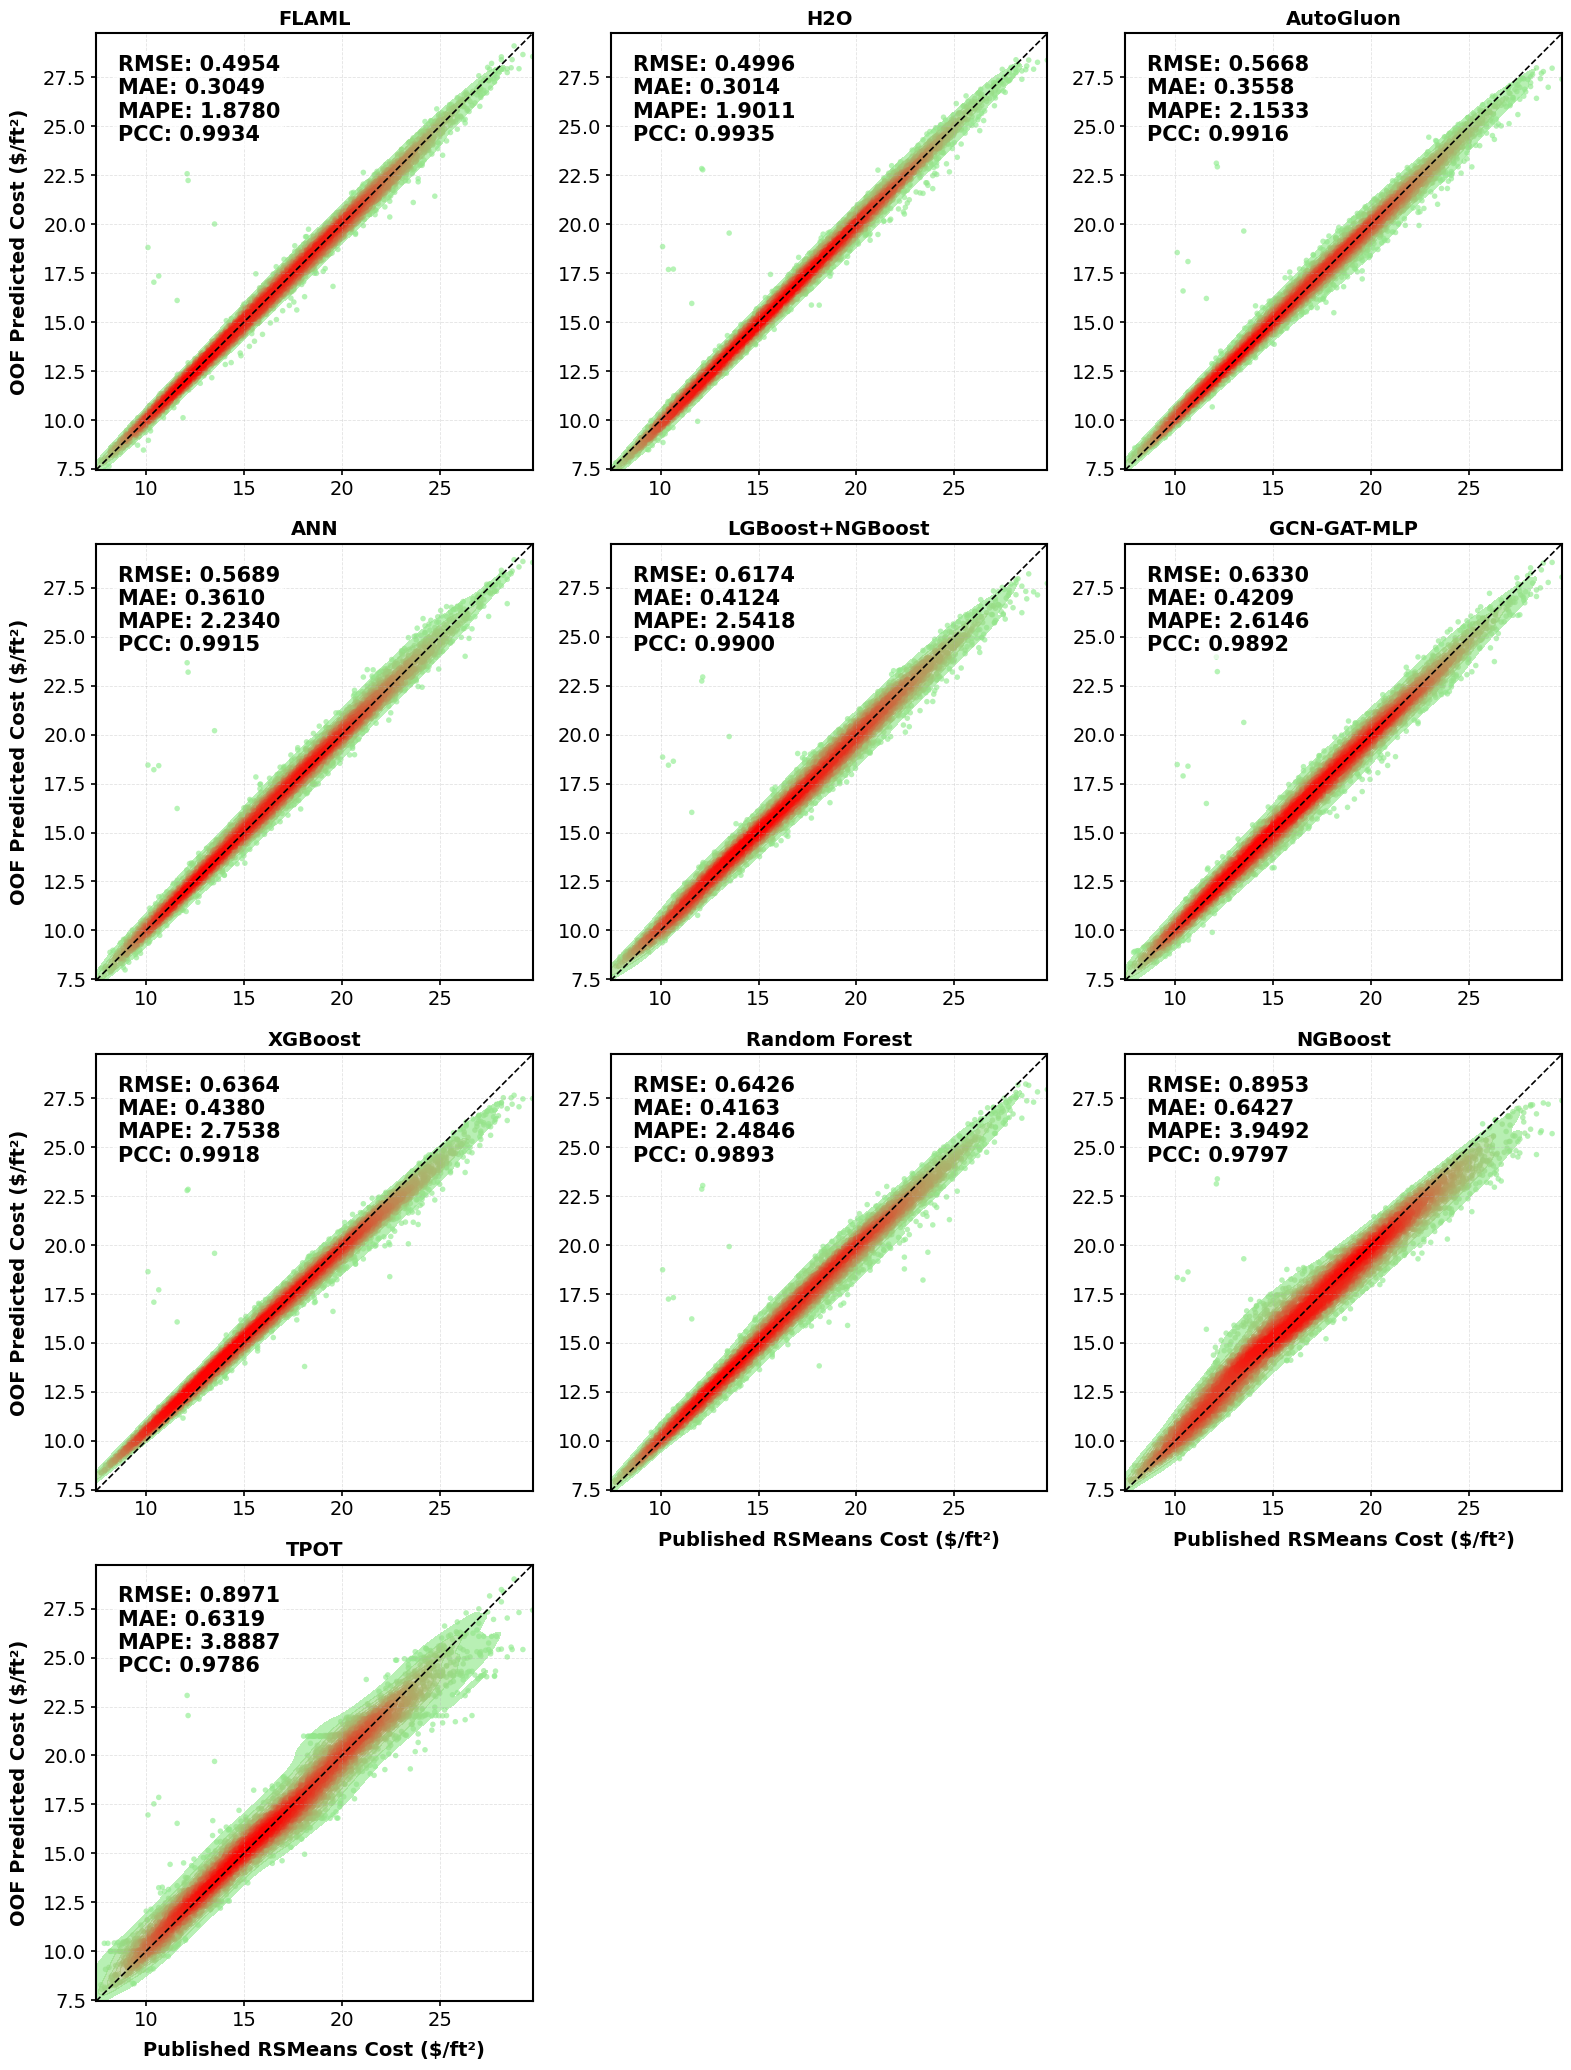

Figure saved to: /content/drive/MyDrive/AutoML/Round2_GroupedCV/figures/Figure4_grouped_oof_actual_vs_predicted_KDE.png


In [ ]:
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde, pearsonr


light_green_pink = LinearSegmentedColormap.from_list(
    "light_green_pink",
    ["lightgreen", "red"],
)

models = results_summary["Model"].tolist()

n_columns = 3
n_rows = int(np.ceil(len(models) / n_columns))

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(16, 5.2 * n_rows),
    squeeze=False,
)


global_min = min(
    prediction_long["True_Cost"].min(),
    prediction_long["Predicted_Cost"].min(),
)

global_max = max(
    prediction_long["True_Cost"].max(),
    prediction_long["Predicted_Cost"].max(),
)

bottom_row_by_column = {
    column: max(
        index // n_columns
        for index in range(len(models))
        if index % n_columns == column
    )
    for column in range(n_columns)
    if any(
        index % n_columns == column
        for index in range(len(models))
    )
}


leftmost_column_by_row = {
    row: min(
        index % n_columns
        for index in range(len(models))
        if index // n_columns == row
    )
    for row in range(n_rows)
    if any(
        index // n_columns == row
        for index in range(len(models))
    )
}

for plot_index, (axis, model_name) in enumerate(
    zip(axes.flat, models)
):
    row_index = plot_index // n_columns
    column_index = plot_index % n_columns
    model_frame = (
        prediction_long
        .query("Model == @model_name")
        .sort_values("RowID")
    )

    actual = model_frame["True_Cost"].to_numpy(dtype=float)
    predictions = model_frame["Predicted_Cost"].to_numpy(dtype=float)


    rmse = np.sqrt(mean_squared_error(actual, predictions))
    mae = mean_absolute_error(actual, predictions)
    nonzero = np.abs(actual) > 1e-12
    mape = (
        np.mean(
            np.abs(
                (actual[nonzero] - predictions[nonzero])
                / actual[nonzero]
            )
        )
        * 100
    )

    if np.std(actual) > 0 and np.std(predictions) > 0:
        pcc, _ = pearsonr(actual, predictions)
    else:
        pcc = np.nan


    xy = np.vstack([actual, predictions])

    try:
        density = gaussian_kde(xy)(xy)
    except np.linalg.LinAlgError:
        density = np.ones(len(actual))


    density_order = np.argsort(density)


    sns.kdeplot(
        x=actual,
        y=predictions,
        cmap=light_green_pink,
        fill=True,
        levels=20,
        thresh=0.03,
        alpha=0.65,
        ax=axis,
    )


    axis.scatter(
        actual[density_order],
        predictions[density_order],
        c=density[density_order],
        cmap=light_green_pink,
        alpha=0.65,
        s=16,
        edgecolors="none",
    )


    axis.plot(
        [global_min, global_max],
        [global_min, global_max],
        color="black",
        linestyle="--",
        linewidth=1.2,
    )

    axis.set_xlim(global_min, global_max)
    axis.set_ylim(global_min, global_max)
    axis.set_aspect("equal", adjustable="box")

    if row_index == bottom_row_by_column[column_index]:
        axis.set_xlabel(
            "Published RSMeans Cost ($/ft²)",
            fontsize=14,
            fontweight="bold",
            labelpad=8,
        )
    else:
        axis.set_xlabel("")


    if column_index == leftmost_column_by_row[row_index]:
        axis.set_ylabel(
            "OOF Predicted Cost ($/ft²)",
            fontsize=14,
            fontweight="bold",
            labelpad=10,
        )
    else:
        axis.set_ylabel("")

    axis.set_title(
    model_name,
    fontsize=14,
    fontweight="bold",
)

    axis.tick_params(
        axis="both",
        labelsize=14,
        width=1.2,
    )


    axis.grid(
        True,
        linestyle="--",
        linewidth=0.6,
        alpha=0.35,
    )


    for spine in axis.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.5)

    metrics_text = (
        f"RMSE: {rmse:.4f}\n"
        f"MAE: {mae:.4f}\n"
        f"MAPE: {mape:.4f}\n"
        f"PCC: {pcc:.4f}"
    )

    axis.text(
        0.05,
        0.95,
        metrics_text,
        transform=axis.transAxes,
        fontsize=15,
        fontweight="bold",
        verticalalignment="top",
        horizontalalignment="left",
        color="black",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.65,
            "pad": 3,
        },
    )


for axis in axes.flat[len(models):]:
    axis.set_visible(False)

fig.tight_layout()

figure_path = (
    FIGURE_DIR
    / "Figure4_grouped_oof_actual_vs_predicted_KDE.png"
)

fig.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", figure_path)

,Model,NumberOfOOFPredictions,MeanResidual,SDResidual,MinimumResidual,MaximumResidual
0,FLAML,4477,0.002164,0.495490,-10.479008,3.317622
1,H2O,4477,0.056093,0.496476,-10.743435,2.233362
2,AutoGluon,4477,-0.007574,0.566811,-11.016671,2.620586
3,ANN,4477,-0.072742,0.564264,-11.571535,2.299005
4,LGBoost+NGBoost,4477,0.022268,0.617076,-10.795332,2.373440
5,GCN-GAT-MLP,4477,-0.000401,0.633022,-11.868084,2.568463
6,XGBoost,4477,-0.011163,0.636353,-10.697685,4.302478
7,Random Forest,4477,0.068149,0.639064,-10.891692,5.187039
8,NGBoost,4477,0.033235,0.894752,-11.230094,3.828514
9,TPOT,4477,0.026192,0.896824,-10.966345,4.610974


Common residual x-axis range: [-12, 12]


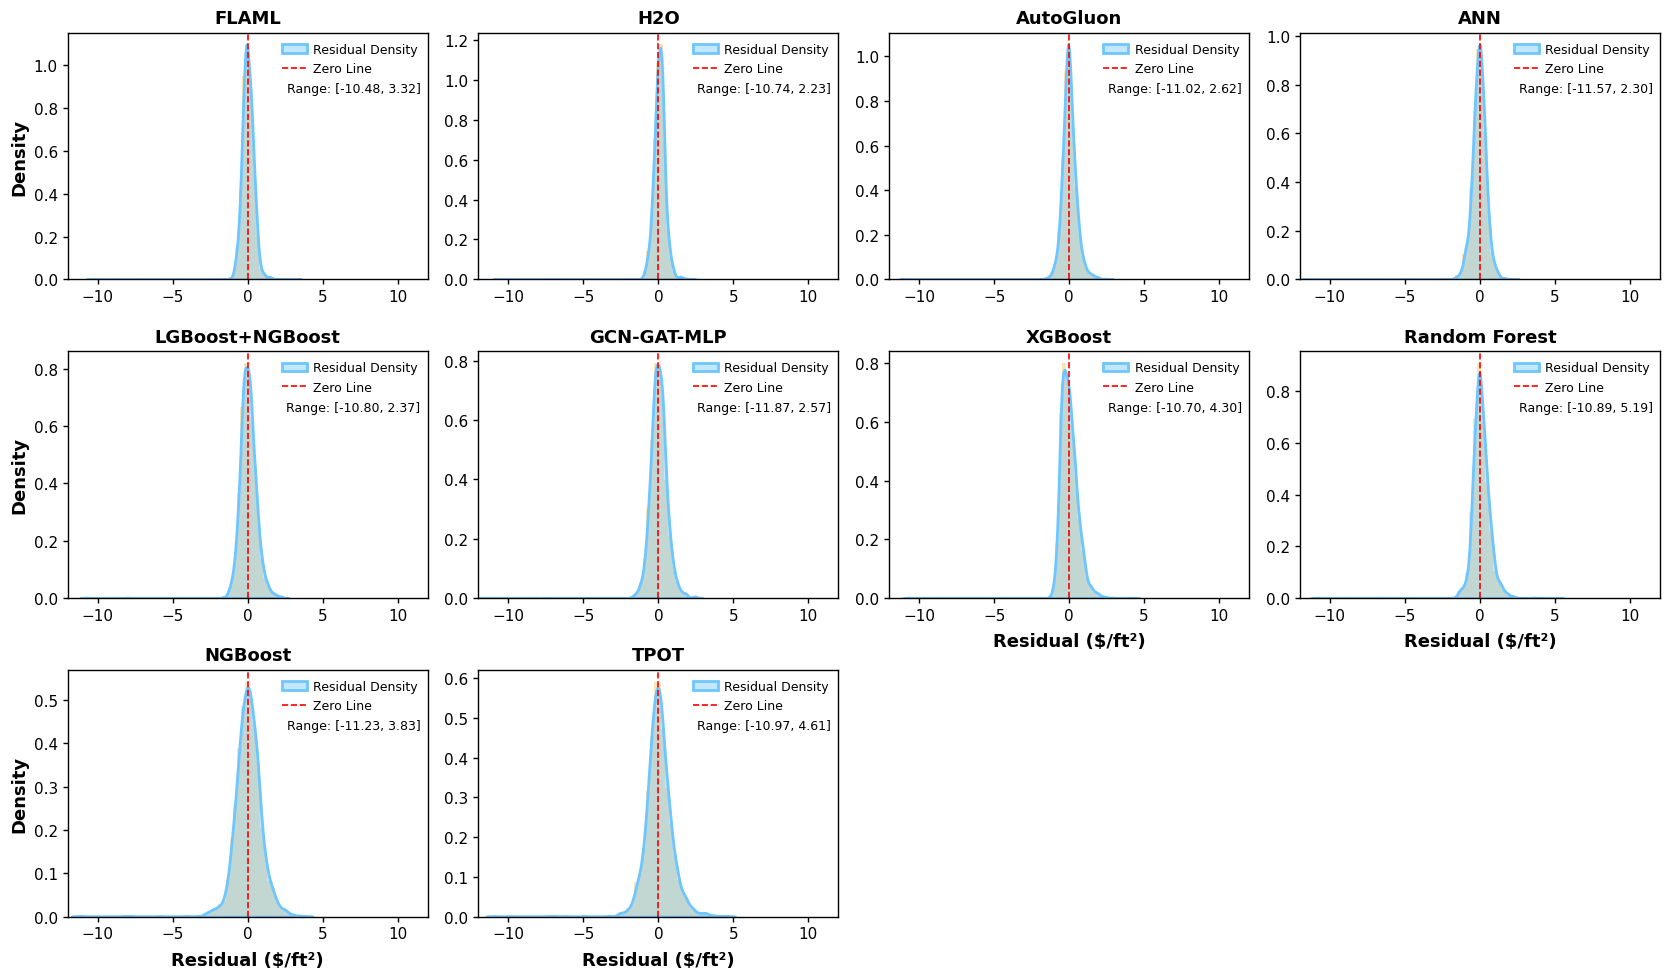

Residual distribution figure saved to: /content/drive/MyDrive/AutoML/Round2_GroupedCV/figures/Figure5_grouped_oof_residual_distributions.png


In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



if "prediction_long" not in globals():
    prediction_files = sorted(
        PREDICTION_DIR.glob(
            "*_oof_predictions.csv"
        )
    )

    if not prediction_files:
        raise FileNotFoundError(
            f"No OOF prediction files were found in: "
            f"{PREDICTION_DIR}"
        )

    prediction_frames = []

    for prediction_file in prediction_files:
        current_frame = pd.read_csv(
            prediction_file
        )


        if "Model" not in current_frame.columns:
            current_model_name = (
                prediction_file.stem
                .replace(
                    "_oof_predictions",
                    "",
                )
            )

            current_frame["Model"] = (
                current_model_name
            )

        prediction_frames.append(
            current_frame
        )

    prediction_long = pd.concat(
        prediction_frames,
        ignore_index=True,
    )



required_columns = {
    "Model",
    "True_Cost",
    "Predicted_Cost",
}

missing_columns = (
    required_columns
    - set(prediction_long.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing required columns: "
        f"{sorted(missing_columns)}"
    )



residual_long = prediction_long.copy()

residual_long["Residual"] = (
    residual_long["True_Cost"]
    - residual_long["Predicted_Cost"]
)


residual_long = residual_long.replace(
    [np.inf, -np.inf],
    np.nan,
)

residual_long = residual_long.dropna(
    subset=[
        "True_Cost",
        "Predicted_Cost",
        "Residual",
    ]
).reset_index(drop=True)



if "results_summary" in globals():
    available_models = set(
        residual_long["Model"].unique()
    )

    models = [
        model_name
        for model_name
        in results_summary["Model"].tolist()
        if model_name in available_models
    ]
else:
    models = (
        residual_long["Model"]
        .drop_duplicates()
        .tolist()
    )

if not models:
    raise ValueError(
        "No models are available for plotting."
    )



residual_long.to_csv(
    TABLE_DIR
    / "all_models_grouped_oof_residuals.csv",
    index=False,
    encoding="utf-8-sig",
)



residual_summary_rows = []

for model_name in models:
    model_residuals = (
        residual_long
        .loc[
            residual_long["Model"]
            == model_name,
            "Residual",
        ]
        .to_numpy(dtype=float)
    )

    residual_summary_rows.append({
        "Model": model_name,
        "NumberOfOOFPredictions": (
            len(model_residuals)
        ),
        "MeanResidual": np.mean(
            model_residuals
        ),
        "SDResidual": np.std(
            model_residuals,
            ddof=1,
        ),
        "MinimumResidual": np.min(
            model_residuals
        ),
        "MaximumResidual": np.max(
            model_residuals
        ),
    })

residual_summary = pd.DataFrame(
    residual_summary_rows
)

display(residual_summary)

residual_summary.to_csv(
    TABLE_DIR
    / "all_models_grouped_oof_residual_summary.csv",
    index=False,
    encoding="utf-8-sig",
)



n_columns = 4

n_rows = int(
    np.ceil(
        len(models) / n_columns
    )
)

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(
        4.2 * n_columns,
        3.3 * n_rows,
    ),
    squeeze=False,
)



all_residuals = (
    residual_long["Residual"]
    .to_numpy(dtype=float)
)

maximum_absolute_residual = np.max(
    np.abs(all_residuals)
)


x_limit = max(
    1,
    int(
        np.ceil(
            maximum_absolute_residual
        )
    ),
)

print(
    f"Common residual x-axis range: "
    f"[-{x_limit}, {x_limit}]"
)



bottom_row_by_column = {
    column: max(
        index // n_columns
        for index in range(len(models))
        if index % n_columns == column
    )
    for column in range(n_columns)
    if any(
        index % n_columns == column
        for index in range(len(models))
    )
}

leftmost_column_by_row = {
    row: min(
        index % n_columns
        for index in range(len(models))
        if index // n_columns == row
    )
    for row in range(n_rows)
    if any(
        index // n_columns == row
        for index in range(len(models))
    )
}



for plot_index, (
    axis,
    model_name,
) in enumerate(
    zip(
        axes.flat,
        models,
    )
):
    row_index = (
        plot_index // n_columns
    )

    column_index = (
        plot_index % n_columns
    )

    model_residuals = (
        residual_long
        .loc[
            residual_long["Model"]
            == model_name,
            "Residual",
        ]
        .to_numpy(dtype=float)
    )

    residual_minimum = np.min(
        model_residuals
    )

    residual_maximum = np.max(
        model_residuals
    )


    sns.histplot(
        x=model_residuals,
        bins=60,
        stat="density",
        color="#FFA500",
        alpha=0.30,
        edgecolor=None,
        linewidth=0,
        ax=axis,
    )


    if (
        len(model_residuals) > 1
        and np.std(model_residuals) > 0
    ):
        sns.kdeplot(
            x=model_residuals,
            fill=True,
            color="#6EC6FF",
            alpha=0.42,
            linewidth=2.0,
            label="Residual Density",
            ax=axis,
        )

    axis.axvline(
        x=0,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label="Zero Line",
    )


    axis.set_xlim(
        -x_limit,
        x_limit,
    )

    axis.set_ylim(
        bottom=0,
    )

    axis.set_title(
        model_name,
        fontsize=13,
        fontweight="bold",
        pad=7,
    )


    if (
        row_index
        == bottom_row_by_column[column_index]
    ):
        axis.set_xlabel(
            "Residual ($/ft²)",
            fontsize=13,
            fontweight="bold",
            labelpad=7,
        )
    else:
        axis.set_xlabel("")


    if (
        column_index
        == leftmost_column_by_row[row_index]
    ):
        axis.set_ylabel(
            "Density",
            fontsize=13,
            fontweight="bold",
        )
    else:
        axis.set_ylabel("")

    axis.tick_params(
        axis="both",
        labelsize=11,
        width=1.0,
    )

    axis.grid(False)


    for spine in axis.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.0)


    axis.legend(
        loc="upper right",
        frameon=False,
        fontsize=9,
        ncol=1,
        handlelength=2.0,
        handletextpad=0.5,
        borderaxespad=0.4,
    )


    axis.text(
        0.98,
        0.80,
        (
            f"Range: "
            f"[{residual_minimum:.2f}, "
            f"{residual_maximum:.2f}]"
        ),
        transform=axis.transAxes,
        fontsize=9,
        fontweight="normal",
        horizontalalignment="right",
        verticalalignment="top",
        #color="black",
    )



for axis in axes.flat[len(models):]:
    axis.set_visible(False)



fig.tight_layout(
    h_pad=1.4,
    w_pad=1.2,
)

residual_figure_path = (
    FIGURE_DIR
    / "Figure5_grouped_oof_residual_distributions.png"
)

fig.savefig(
    residual_figure_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print(
    "Residual distribution figure saved to:",
    residual_figure_path,
)

In [ ]:
import itertools
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon, rankdata
from statsmodels.stats.multitest import multipletests
ALPHA = 0.05


AUTOML_MODELS = [
    "FLAML",
    "H2O",
    "AutoGluon",
    "TPOT",
]


required_columns = {
    "Model",
    "True_Cost",
    "Predicted_Cost",
}

missing_columns = (
    required_columns
    - set(prediction_long.columns)
)

if missing_columns:
    raise ValueError(
        f"prediction_long is missing columns: "
        f"{sorted(missing_columns)}"
    )


if "ConfigurationID" not in prediction_long.columns:
    if (
        "RowID" in prediction_long.columns
        and "RowID" in data.columns
        and "ConfigurationID" in data.columns
    ):
        configuration_map = (
            data[
                [
                    "RowID",
                    "ConfigurationID",
                ]
            ]
            .drop_duplicates("RowID")
        )

        prediction_long = prediction_long.merge(
            configuration_map,
            on="RowID",
            how="left",
            validate="many_to_one",
        )
    else:
        raise ValueError(
            "ConfigurationID is not available. "
            "Run the grouped-validation data-preparation "
            "cell before conducting the Wilcoxon tests."
        )


if prediction_long["ConfigurationID"].isna().any():
    raise ValueError(
        "Some OOF predictions do not have a "
        "ConfigurationID."
    )



statistical_data = prediction_long.copy()

statistical_data["AbsoluteError"] = np.abs(
    statistical_data["True_Cost"]
    - statistical_data["Predicted_Cost"]
)

statistical_data = statistical_data.replace(
    [np.inf, -np.inf],
    np.nan,
)

statistical_data = statistical_data.dropna(
    subset=[
        "Model",
        "ConfigurationID",
        "AbsoluteError",
    ]
).reset_index(drop=True)



configuration_errors = (
    statistical_data
    .groupby(
        [
            "ConfigurationID",
            "Model",
        ],
        as_index=False,
    )
    .agg(
        ConfigurationMAE=(
            "AbsoluteError",
            "mean",
        ),
        NumberOfRecords=(
            "AbsoluteError",
            "size",
        ),
    )
)

configuration_errors.to_csv(
    TABLE_DIR
    / "configuration_level_absolute_errors.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Number of configurations:",
    configuration_errors[
        "ConfigurationID"
    ].nunique(),
)

print(
    "Models:",
    configuration_errors[
        "Model"
    ].unique().tolist(),
)



configuration_error_matrix = (
    configuration_errors
    .pivot(
        index="ConfigurationID",
        columns="Model",
        values="ConfigurationMAE",
    )
    .sort_index()
)

available_models = (
    configuration_error_matrix
    .columns
    .tolist()
)

configuration_error_matrix.to_csv(
    TABLE_DIR
    / "configuration_level_MAE_matrix.csv",
    encoding="utf-8-sig",
)



def paired_rank_biserial(differences):
    """
    differences = Model A error - Model B error

    r_rb < 0:
        Model A generally has lower errors.

    r_rb > 0:
        Model B generally has lower errors.
    """
    differences = np.asarray(
        differences,
        dtype=float,
    )

    differences = differences[
        np.isfinite(differences)
    ]


    nonzero_differences = differences[
        differences != 0
    ]

    if len(nonzero_differences) == 0:
        return 0.0, 0.0, 0.0

    absolute_ranks = rankdata(
        np.abs(nonzero_differences),
        method="average",
    )

    positive_rank_sum = np.sum(
        absolute_ranks[
            nonzero_differences > 0
        ]
    )

    negative_rank_sum = np.sum(
        absolute_ranks[
            nonzero_differences < 0
        ]
    )

    total_rank_sum = (
        positive_rank_sum
        + negative_rank_sum
    )

    rank_biserial = (
        positive_rank_sum
        - negative_rank_sum
    ) / total_rank_sum

    return (
        float(rank_biserial),
        float(positive_rank_sum),
        float(negative_rank_sum),
    )



def effect_size_label(rank_biserial):
    absolute_effect = abs(
        rank_biserial
    )

    if absolute_effect < 0.10:
        return "Negligible"
    elif absolute_effect < 0.30:
        return "Small"
    elif absolute_effect < 0.50:
        return "Moderate"
    else:
        return "Large"

pairwise_rows = []

for model_a, model_b in itertools.combinations(
    available_models,
    2,
):
    paired_errors = (
        configuration_error_matrix[
            [
                model_a,
                model_b,
            ]
        ]
        .dropna()
    )

    errors_a = (
        paired_errors[model_a]
        .to_numpy(dtype=float)
    )

    errors_b = (
        paired_errors[model_b]
        .to_numpy(dtype=float)
    )


    differences = np.round(
        errors_a - errors_b,
        decimals=12,
    )

    number_of_pairs = len(
        differences
    )

    number_of_nonzero_pairs = int(
        np.sum(differences != 0)
    )

    if number_of_pairs < 2:
        wilcoxon_statistic = np.nan
        raw_p_value = np.nan

    elif number_of_nonzero_pairs == 0:
        wilcoxon_statistic = 0.0
        raw_p_value = 1.0

    else:
        test_result = wilcoxon(
            differences,
            alternative="two-sided",
            zero_method="wilcox",
            correction=False,
            method="auto",
        )

        wilcoxon_statistic = float(
            test_result.statistic
        )

        raw_p_value = float(
            test_result.pvalue
        )

    (
        rank_biserial,
        positive_rank_sum,
        negative_rank_sum,
    ) = paired_rank_biserial(
        differences
    )


    if np.isclose(
        rank_biserial,
        0.0,
        atol=1e-12,
    ):
        lower_error_model = (
            "No directional difference"
        )
    elif rank_biserial < 0:
        lower_error_model = model_a
    else:
        lower_error_model = model_b

    pairwise_rows.append({
        "ModelA": model_a,
        "ModelB": model_b,
        "NConfigurations": number_of_pairs,
        "NNonzeroDifferences": (
            number_of_nonzero_pairs
        ),
        "MeanConfigurationMAE_A": (
            np.mean(errors_a)
        ),
        "MeanConfigurationMAE_B": (
            np.mean(errors_b)
        ),
        "MedianConfigurationMAE_A": (
            np.median(errors_a)
        ),
        "MedianConfigurationMAE_B": (
            np.median(errors_b)
        ),
        "MeanDifference_A_minus_B": (
            np.mean(differences)
        ),
        "MedianDifference_A_minus_B": (
            np.median(differences)
        ),
        "WilcoxonStatistic": (
            wilcoxon_statistic
        ),
        "RawPValue": raw_p_value,
        "RankSumPositive": (
            positive_rank_sum
        ),
        "RankSumNegative": (
            negative_rank_sum
        ),
        "RankBiserialCorrelation": (
            rank_biserial
        ),
        "EffectSizeMagnitude": (
            effect_size_label(
                rank_biserial
            )
        ),
        "LowerErrorDirection": (
            lower_error_model
        ),
    })


pairwise_results = pd.DataFrame(
    pairwise_rows
)



valid_p_mask = (
    pairwise_results["RawPValue"]
    .notna()
)

holm_reject = np.full(
    len(pairwise_results),
    False,
    dtype=bool,
)

holm_adjusted_p = np.full(
    len(pairwise_results),
    np.nan,
    dtype=float,
)

if valid_p_mask.any():
    (
        valid_reject,
        valid_adjusted_p,
        _,
        _,
    ) = multipletests(
        pairwise_results.loc[
            valid_p_mask,
            "RawPValue",
        ],
        alpha=ALPHA,
        method="holm",
    )

    holm_reject[
        valid_p_mask.to_numpy()
    ] = valid_reject

    holm_adjusted_p[
        valid_p_mask.to_numpy()
    ] = valid_adjusted_p


pairwise_results[
    "HolmAdjustedPValue"
] = holm_adjusted_p

pairwise_results[
    "SignificantAfterHolm"
] = holm_reject



pairwise_results = (
    pairwise_results
    .sort_values(
        [
            "HolmAdjustedPValue",
            "RawPValue",
        ],
        na_position="last",
    )
    .reset_index(drop=True)
)



all_pairwise_path = (
    TABLE_DIR
    / "Wilcoxon_configuration_level_all_models_Holm.csv"
)

pairwise_results.to_csv(
    all_pairwise_path,
    index=False,
    encoding="utf-8-sig",
)

print(
    "\n=== All-model pairwise Wilcoxon tests ==="
)

display(
    pairwise_results[
        [
            "ModelA",
            "ModelB",
            "NConfigurations",
            "MedianDifference_A_minus_B",
            "RawPValue",
            "HolmAdjustedPValue",
            "SignificantAfterHolm",
            "RankBiserialCorrelation",
            "EffectSizeMagnitude",
            "LowerErrorDirection",
        ]
    ]
)



available_automl_models = [
    model
    for model in AUTOML_MODELS
    if model in available_models
]

automl_pairwise_results = (
    pairwise_results[
        pairwise_results["ModelA"].isin(
            available_automl_models
        )
        & pairwise_results["ModelB"].isin(
            available_automl_models
        )
    ]
    .copy()
    .reset_index(drop=True)
)

automl_pairwise_path = (
    TABLE_DIR
    / "Wilcoxon_AutoML_pairwise_from_all_model_Holm.csv"
)

automl_pairwise_results.to_csv(
    automl_pairwise_path,
    index=False,
    encoding="utf-8-sig",
)

print(
    "\n=== AutoML-framework comparisons ==="
)

display(
    automl_pairwise_results[
        [
            "ModelA",
            "ModelB",
            "NConfigurations",
            "MeanConfigurationMAE_A",
            "MeanConfigurationMAE_B",
            "MedianDifference_A_minus_B",
            "RawPValue",
            "HolmAdjustedPValue",
            "SignificantAfterHolm",
            "RankBiserialCorrelation",
            "EffectSizeMagnitude",
            "LowerErrorDirection",
        ]
    ]
)


if "FLAML" in available_models:
    flaml_comparisons = (
        pairwise_results[
            (
                pairwise_results["ModelA"]
                == "FLAML"
            )
            |
            (
                pairwise_results["ModelB"]
                == "FLAML"
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

    flaml_comparisons.to_csv(
        TABLE_DIR
        / "Wilcoxon_FLAML_vs_other_models_Holm.csv",
        index=False,
        encoding="utf-8-sig",
    )

    print(
        "\n=== FLAML versus other models ==="
    )

    display(
        flaml_comparisons[
            [
                "ModelA",
                "ModelB",
                "NConfigurations",
                "RawPValue",
                "HolmAdjustedPValue",
                "SignificantAfterHolm",
                "RankBiserialCorrelation",
                "EffectSizeMagnitude",
                "LowerErrorDirection",
            ]
        ]
    )



holm_p_matrix = pd.DataFrame(
    np.ones(
        (
            len(available_models),
            len(available_models),
        )
    ),
    index=available_models,
    columns=available_models,
)

effect_size_matrix = pd.DataFrame(
    np.zeros(
        (
            len(available_models),
            len(available_models),
        )
    ),
    index=available_models,
    columns=available_models,
)

for _, row in pairwise_results.iterrows():
    model_a = row["ModelA"]
    model_b = row["ModelB"]

    adjusted_p = row[
        "HolmAdjustedPValue"
    ]

    effect_size = row[
        "RankBiserialCorrelation"
    ]

    holm_p_matrix.loc[
        model_a,
        model_b,
    ] = adjusted_p

    holm_p_matrix.loc[
        model_b,
        model_a,
    ] = adjusted_p


    effect_size_matrix.loc[
        model_a,
        model_b,
    ] = effect_size

    effect_size_matrix.loc[
        model_b,
        model_a,
    ] = -effect_size


holm_p_matrix.to_csv(
    TABLE_DIR
    / "Wilcoxon_Holm_adjusted_pvalue_matrix.csv",
    encoding="utf-8-sig",
)

effect_size_matrix.to_csv(
    TABLE_DIR
    / "Wilcoxon_rank_biserial_effect_matrix.csv",
    encoding="utf-8-sig",
)


print(
    "\nSaved:"
)

print(
    all_pairwise_path
)

print(
    automl_pairwise_path
)

Number of configurations: 217
Models: ['ANN', 'AutoGluon', 'FLAML', 'GCN-GAT-MLP', 'H2O', 'LGBoost+NGBoost', 'NGBoost', 'Random Forest', 'TPOT', 'XGBoost']

=== All-model pairwise Wilcoxon tests ===


,ModelA,ModelB,NConfigurations,MedianDifference_A_minus_B,RawPValue,HolmAdjustedPValue,SignificantAfterHolm,RankBiserialCorrelation,EffectSizeMagnitude,LowerErrorDirection
0,H2O,NGBoost,217,-0.320260,2.458735e-34,1.106431e-32,True,-0.956707,Large,H2O
1,FLAML,NGBoost,217,-0.322792,1.925416e-33,8.471830e-32,True,-0.943517,Large,FLAML
2,LGBoost+NGBoost,NGBoost,217,-0.221241,2.362577e-32,1.015908e-30,True,-0.927197,Large,LGBoost+NGBoost
3,H2O,TPOT,217,-0.271523,1.417449e-31,5.953285e-30,True,-0.915360,Large,H2O
4,FLAML,TPOT,217,-0.257713,2.205605e-30,9.042981e-29,True,-0.896926,Large,FLAML
5,NGBoost,XGBoost,217,0.202918,2.625808e-30,1.050323e-28,True,0.895743,Large,XGBoost
6,AutoGluon,NGBoost,217,-0.282255,6.120098e-29,2.386838e-27,True,-0.874096,Large,AutoGluon
7,AutoGluon,TPOT,217,-0.214191,3.743865e-26,1.422669e-24,True,-0.828267,Large,AutoGluon
8,ANN,NGBoost,217,-0.285347,5.167336e-26,1.911914e-24,True,-0.825899,Large,ANN
9,NGBoost,Random Forest,217,0.248112,4.059035e-25,1.461253e-23,True,0.810595,Large,Random Forest



=== AutoML-framework comparisons ===


,ModelA,ModelB,NConfigurations,MeanConfigurationMAE_A,MeanConfigurationMAE_B,MedianDifference_A_minus_B,RawPValue,HolmAdjustedPValue,SignificantAfterHolm,RankBiserialCorrelation,EffectSizeMagnitude,LowerErrorDirection
0,H2O,TPOT,217,0.302291,0.633978,-0.271523,1.417449e-31,5.953285e-30,True,-0.915360,Large,H2O
1,FLAML,TPOT,217,0.305692,0.633978,-0.257713,2.205605e-30,9.042981e-29,True,-0.896926,Large,FLAML
2,AutoGluon,TPOT,217,0.357234,0.633978,-0.214191,3.743865e-26,1.422669e-24,True,-0.828267,Large,AutoGluon
3,AutoGluon,H2O,217,0.357234,0.302291,0.025107,1.344527e-04,1.882337e-03,True,0.298947,Small,H2O
4,AutoGluon,FLAML,217,0.357234,0.305692,0.038432,6.976601e-04,8.371922e-03,True,0.265463,Small,FLAML
5,FLAML,H2O,217,0.305692,0.302291,0.007869,7.422735e-01,1.000000e+00,False,0.025747,Negligible,H2O



=== FLAML versus other models ===


,ModelA,ModelB,NConfigurations,RawPValue,HolmAdjustedPValue,SignificantAfterHolm,RankBiserialCorrelation,EffectSizeMagnitude,LowerErrorDirection
0,FLAML,NGBoost,217,1.925416e-33,8.471830e-32,True,-0.943517,Large,FLAML
1,FLAML,TPOT,217,2.205605e-30,9.042981e-29,True,-0.896926,Large,FLAML
2,FLAML,XGBoost,217,5.789296e-16,1.505217e-14,True,-0.633704,Large,FLAML
3,FLAML,LGBoost+NGBoost,217,1.331899e-14,3.329747e-13,True,-0.603095,Large,FLAML
4,FLAML,GCN-GAT-MLP,217,1.272708e-13,3.054500e-12,True,-0.580096,Large,FLAML
5,FLAML,Random Forest,217,1.281402e-07,2.690944e-06,True,-0.413520,Moderate,FLAML
6,ANN,FLAML,217,2.772857e-04,3.604714e-03,True,0.284657,Small,FLAML
7,AutoGluon,FLAML,217,6.976601e-04,8.371922e-03,True,0.265463,Small,FLAML
8,FLAML,H2O,217,7.422735e-01,1.000000e+00,False,0.025747,Negligible,H2O



Saved:
/content/drive/MyDrive/AutoML/Round2_GroupedCV/tables/Wilcoxon_configuration_level_all_models_Holm.csv
/content/drive/MyDrive/AutoML/Round2_GroupedCV/tables/Wilcoxon_AutoML_pairwise_from_all_model_Holm.csv


## 7. Configuration-level inference, Holm correction, and effect sizes



In [ ]:
def configuration_error_table(predictions):
    frame = predictions.copy()
    frame["AbsoluteError"] = np.abs(frame["True_Cost"] - frame["Predicted_Cost"])
    frame["SquaredError"] = (frame["True_Cost"] - frame["Predicted_Cost"]) ** 2
    frame["AbsolutePercentageError"] = frame["AbsoluteError"] / frame["True_Cost"] * 100
    grouped = (
        frame.groupby(["Model", "ConfigurationID"])
        .agg(
            MAE=("AbsoluteError", "mean"),
            MSE=("SquaredError", "mean"),
            MAPE_percent=("AbsolutePercentageError", "mean"),
        )
        .reset_index()
    )
    grouped["RMSE"] = np.sqrt(grouped["MSE"])
    return grouped.drop(columns="MSE")


def paired_rank_biserial(differences):
    differences = np.asarray(differences, dtype=float)
    differences = differences[differences != 0]
    if len(differences) == 0:
        return 0.0
    ranks = stats.rankdata(np.abs(differences))
    positive = ranks[differences > 0].sum()
    negative = ranks[differences < 0].sum()
    return float((positive - negative) / (positive + negative))


configuration_errors = configuration_error_table(prediction_long)
configuration_errors.to_csv(TABLE_DIR / "configuration_level_errors.csv", index=False, encoding="utf-8-sig")

automl_names = [name for name in ["FLAML", "AutoGluon", "H2O", "TPOT"] if name in configuration_errors["Model"].unique()]
all_names = sorted(configuration_errors["Model"].unique())
comparisons = []
for i, model_a in enumerate(all_names):
    for model_b in all_names[i + 1:]:
        # Include all AutoML-to-AutoML tests and all AutoML-to-baseline tests.
        if not (model_a in automl_names or model_b in automl_names):
            continue
        for metric in ["RMSE", "MAE", "MAPE_percent"]:
            paired = (
                configuration_errors.loc[configuration_errors["Model"].isin([model_a, model_b])]
                .pivot(index="ConfigurationID", columns="Model", values=metric)
                .dropna()
            )
            difference = paired[model_a] - paired[model_b]
            if np.allclose(difference, 0):
                statistic, p_value = 0.0, 1.0
            else:
                statistic, p_value = stats.wilcoxon(difference, alternative="two-sided", zero_method="wilcox")
            comparisons.append({
                "Model_A": model_a,
                "Model_B": model_b,
                "Metric": metric,
                "Configurations": len(paired),
                "Median_A_minus_B": float(np.median(difference)),
                "RankBiserial_A_minus_B": paired_rank_biserial(difference),
                "WilcoxonStatistic": statistic,
                "P_raw": p_value,
            })

statistical_tests = pd.DataFrame(comparisons)
statistical_tests["P_Holm"] = multipletests(statistical_tests["P_raw"], method="holm")[1]
statistical_tests["Significant_Holm_0.05"] = statistical_tests["P_Holm"] < 0.05
statistical_tests = statistical_tests.sort_values(["Metric", "P_Holm"]).reset_index(drop=True)
display(statistical_tests)
statistical_tests.to_csv(TABLE_DIR / "Table4_configuration_level_wilcoxon_holm.csv", index=False, encoding="utf-8-sig")

,Model_A,Model_B,Metric,Configurations,Median_A_minus_B,RankBiserial_A_minus_B,WilcoxonStatistic,P_raw,P_Holm,Significant_Holm_0.05
0,H2O,NGBoost,MAE,217,-0.320260,-0.956707,512.0,2.458735e-34,2.163687e-32,True
1,FLAML,NGBoost,MAE,217,-0.322792,-0.943517,668.0,1.925416e-33,1.617349e-31,True
2,H2O,TPOT,MAE,217,-0.271523,-0.915360,1001.0,1.417449e-31,1.148134e-29,True
3,FLAML,TPOT,MAE,217,-0.257713,-0.896926,1219.0,2.205605e-30,1.720372e-28,True
4,AutoGluon,NGBoost,MAE,217,-0.282255,-0.874096,1489.0,6.120098e-29,4.651275e-27,True
...,...,...,...,...,...,...,...,...,...,...
85,AutoGluon,FLAML,RMSE,217,0.035046,0.315267,8098.0,5.659244e-05,1.188441e-03,True
86,AutoGluon,Random Forest,RMSE,217,-0.022957,-0.222932,9190.0,4.409413e-03,4.850354e-02,True
87,NGBoost,TPOT,RMSE,217,0.064486,0.161629,9915.0,3.898731e-02,3.508858e-01,False
88,ANN,AutoGluon,RMSE,217,0.026860,0.063036,11081.0,4.207612e-01,1.000000e+00,False


In [ ]:
def cluster_bootstrap_metrics(model_frame, n_bootstrap=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    grouped = {key: value for key, value in model_frame.groupby("ConfigurationID")}
    configuration_ids = np.array(list(grouped))
    samples = []
    for _ in range(n_bootstrap):
        drawn = rng.choice(configuration_ids, size=len(configuration_ids), replace=True)
        y_true = np.concatenate([grouped[group]["True_Cost"].to_numpy() for group in drawn])
        y_pred = np.concatenate([grouped[group]["Predicted_Cost"].to_numpy() for group in drawn])
        samples.append(regression_metrics(y_true, y_pred))
    sample_frame = pd.DataFrame(samples)
    point = regression_metrics(model_frame["True_Cost"], model_frame["Predicted_Cost"])
    rows = []
    for metric, value in point.items():
        rows.append({
            "Metric": metric,
            "Estimate": value,
            "CI95_Lower": sample_frame[metric].quantile(0.025),
            "CI95_Upper": sample_frame[metric].quantile(0.975),
        })
    return pd.DataFrame(rows)


ci_tables = []
for model_name, model_frame in prediction_long.groupby("Model"):
    ci = cluster_bootstrap_metrics(model_frame)
    ci.insert(0, "Model", model_name)
    ci_tables.append(ci)
clustered_ci = pd.concat(ci_tables, ignore_index=True)
display(clustered_ci)
clustered_ci.to_csv(TABLE_DIR / "cluster_bootstrap_95CI_by_configuration.csv", index=False, encoding="utf-8-sig")

,Model,Metric,Estimate,CI95_Lower,CI95_Upper
0,ANN,RMSE,0.568871,0.481336,0.655892
1,ANN,MAE,0.360957,0.335494,0.390232
2,ANN,MAPE_percent,2.233990,2.061841,2.435416
3,AutoGluon,RMSE,0.566799,0.486640,0.651324
4,AutoGluon,MAE,0.355796,0.325837,0.389797
5,AutoGluon,MAPE_percent,2.153258,1.964635,2.356139
6,FLAML,RMSE,0.495440,0.412394,0.580244
7,FLAML,MAE,0.304931,0.281265,0.329895
8,FLAML,MAPE_percent,1.877974,1.725935,2.038634
9,GCN-GAT-MLP,RMSE,0.632952,0.551462,0.718733


## 8. Figure 3 sensitivity analysis with active subsampling



Permutation importance: fold 1/5
Permutation importance: fold 2/5
Permutation importance: fold 3/5
Permutation importance: fold 4/5
Permutation importance: fold 5/5

=== Grouped permutation feature importance ===


,Feature,MeanMAEIncrease,SDFoldMAEIncrease
0,Formwork,2.547246,0.054244
1,Tributary Area,1.798654,0.066473
2,Type,1.254092,0.064320
3,Concrete,1.218492,0.027878
4,Superimposed Load,0.775388,0.027903


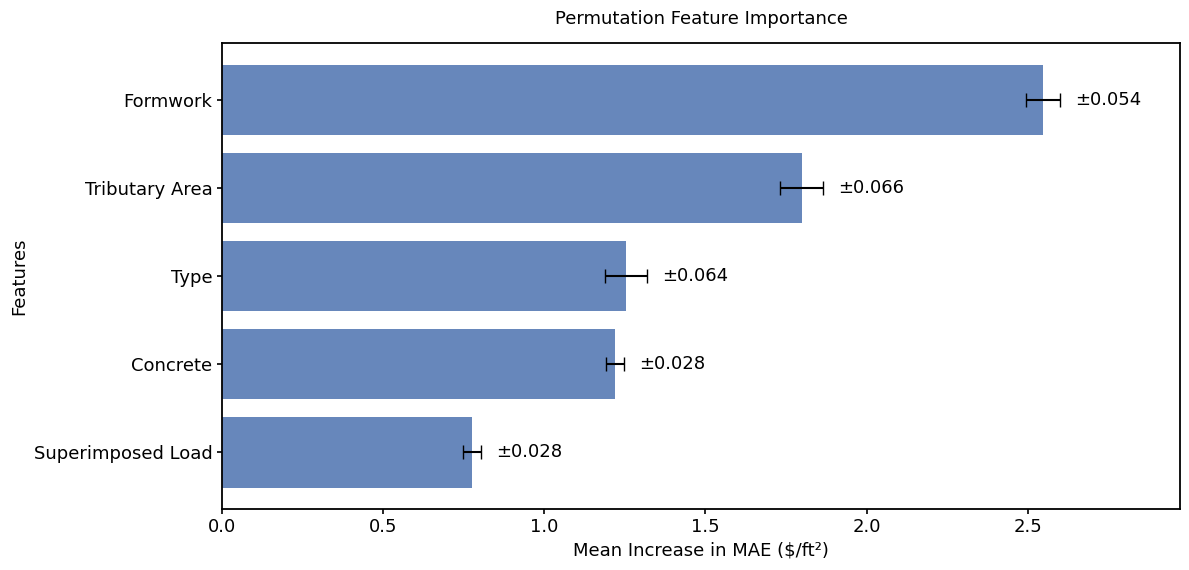

Feature importance figure saved to: /content/drive/MyDrive/AutoML/Round2_GroupedCV/figures/Figure3a_grouped_permutation_feature_importance.png

Hyperparameter sensitivity: learning_rate

Hyperparameter sensitivity: max_depth

Hyperparameter sensitivity: subsample

=== Grouped hyperparameter sensitivity ===


,TestedParameter,ParameterValue,MeanFoldMAE,SDFoldMAE,GlobalOOF_MAE,PredictionHash,SubsampleFreq
0,learning_rate,0.001,2.829313,0.040613,2.829511,f76d1a07f5c162d5d5c80f7263cb0c3b1f41051bc401b4...,1
1,learning_rate,0.005,1.276328,0.035042,1.276454,06eed45d9b2c55aa48a21a67d5d20e6417e63dd1fe20de...,1
2,learning_rate,0.010,0.636165,0.022668,0.636238,85a4988d040e81b63931341e1c1b2d6173ec209acf0b6d...,1
3,learning_rate,0.050,0.310011,0.026079,0.309869,6c525b37f3d7913d168dd553ffa1f7d0bc36e1ff9cf38e...,1
4,learning_rate,0.100,0.305463,0.023690,0.305340,39abc0e8c2472369d5f87ac4197c978b915478af9bb9ca...,1
5,learning_rate,0.200,0.314307,0.026381,0.314131,fe3746e180595681cb168aecd5845a350ca458a1e798c6...,1
6,learning_rate,0.300,0.324634,0.026768,0.324485,d75f1845828dfa341043c647802d19db53b1b0163a335d...,1
7,max_depth,2.000,0.647015,0.048279,0.647180,de4dc988f367bcc199e54d74aaaea013319f0227081cc2...,1
8,max_depth,4.000,0.333255,0.023492,0.333150,4fe15dadefdeb9862780945fb784349ef901ad7bc0d855...,1
9,max_depth,6.000,0.310011,0.026079,0.309869,6c525b37f3d7913d168dd553ffa1f7d0bc36e1ff9cf38e...,1


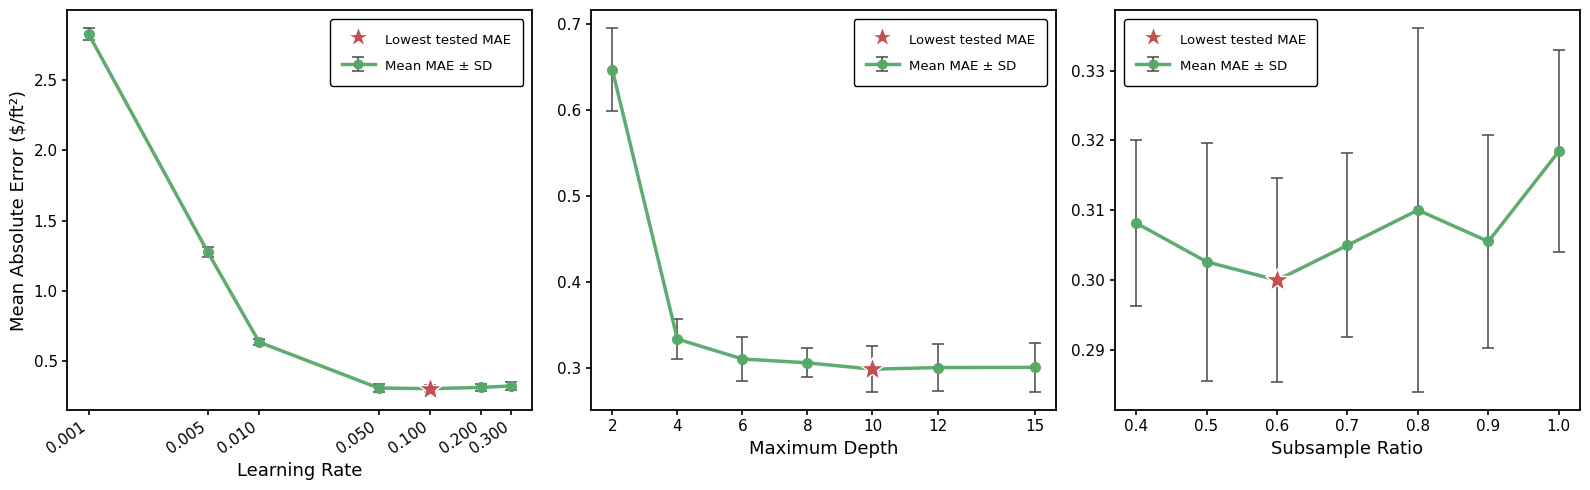

Hyperparameter sensitivity figure saved to: /content/drive/MyDrive/AutoML/Round2_GroupedCV/figures/Figure3b_grouped_hyperparameter_sensitivity.png


In [ ]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error

encoded_features = pd.get_dummies(
    data[FEATURES],
    columns=["Type"],
    drop_first=False,
)

reference_params = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 6,
    "num_leaves": 31,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 1.0,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}



N_PERMUTATION_REPEATS = 30
type_dummy_columns = [
    column
    for column in encoded_features.columns
    if str(column).startswith("Type_")
]

feature_column_groups = {
    "Type": type_dummy_columns,
    "Tributary Area": ["Tributary Area"],
    "Superimposed Load": ["Superimposed Load"],
    "Formwork": ["Formwork"],
    "Concrete": ["Concrete"],
}


for feature_name, encoded_columns in feature_column_groups.items():
    if len(encoded_columns) == 0:
        raise ValueError(
            f"No encoded columns were found for feature: "
            f"{feature_name}"
        )

missing_columns = [
    column
    for encoded_columns in feature_column_groups.values()
    for column in encoded_columns
    if column not in encoded_features.columns
]

if missing_columns:
    raise ValueError(
        f"Missing encoded feature columns: {missing_columns}"
    )


feature_repeat_rows = []
feature_fold_rows = []

for fold, (train_idx, test_idx) in enumerate(
    outer_splits,
    start=1,
):
    print(
        f"Permutation importance: fold "
        f"{fold}/{len(outer_splits)}"
    )

    x_train = encoded_features.iloc[train_idx].copy()
    x_test = encoded_features.iloc[test_idx].copy()

    y_train = (
        data.iloc[train_idx][TARGET]
        .to_numpy(dtype=float)
    )
    y_test = (
        data.iloc[test_idx][TARGET]
        .to_numpy(dtype=float)
    )


    feature_model = LGBMRegressor(
        **reference_params
    )

    feature_model.fit(
        x_train,
        y_train,
    )

    baseline_predictions = feature_model.predict(
        x_test
    )

    baseline_mae = mean_absolute_error(
        y_test,
        baseline_predictions,
    )

    for feature_number, (
        feature_name,
        encoded_columns,
    ) in enumerate(
        feature_column_groups.items()
    ):
        repeat_increases = []

        for repeat in range(
            N_PERMUTATION_REPEATS
        ):

            rng = np.random.default_rng(
                SEED
                + fold * 10000
                + feature_number * 100
                + repeat
            )

            permutation = rng.permutation(
                len(x_test)
            )

            x_permuted = x_test.copy()


            x_permuted.loc[:, encoded_columns] = (
                x_test.loc[:, encoded_columns]
                .to_numpy()[permutation]
            )

            permuted_predictions = (
                feature_model.predict(
                    x_permuted
                )
            )

            permuted_mae = mean_absolute_error(
                y_test,
                permuted_predictions,
            )

            mae_increase = (
                permuted_mae - baseline_mae
            )

            repeat_increases.append(
                mae_increase
            )

            feature_repeat_rows.append({
                "Fold": fold,
                "Feature": feature_name,
                "Repeat": repeat + 1,
                "BaselineMAE": baseline_mae,
                "PermutedMAE": permuted_mae,
                "MAEIncrease": mae_increase,
            })


        feature_fold_rows.append({
            "Fold": fold,
            "Feature": feature_name,
            "BaselineMAE": baseline_mae,
            "MeanPermutedMAE": (
                baseline_mae
                + np.mean(repeat_increases)
            ),
            "MeanMAEIncrease": np.mean(
                repeat_increases
            ),
            "SDRepeatedPermutations": np.std(
                repeat_increases,
                ddof=1,
            ),
        })


feature_repeat_results = pd.DataFrame(
    feature_repeat_rows
)

feature_fold_results = pd.DataFrame(
    feature_fold_rows
)


feature_importance = (
    feature_fold_results
    .groupby(
        "Feature",
        as_index=False,
    )
    .agg(
        MeanMAEIncrease=(
            "MeanMAEIncrease",
            "mean",
        ),
        SDFoldMAEIncrease=(
            "MeanMAEIncrease",
            lambda values: np.std(
                values,
                ddof=1,
            ),
        ),
    )
    .sort_values(
        "MeanMAEIncrease",
        ascending=False,
    )
    .reset_index(drop=True)
)

print(
    "\n=== Grouped permutation "
    "feature importance ==="
)

display(feature_importance)



feature_repeat_results.to_csv(
    TABLE_DIR
    / "permutation_feature_importance_repeats.csv",
    index=False,
    encoding="utf-8-sig",
)

feature_fold_results.to_csv(
    TABLE_DIR
    / "permutation_feature_importance_by_fold.csv",
    index=False,
    encoding="utf-8-sig",
)

feature_importance.to_csv(
    TABLE_DIR
    / "permutation_feature_importance_summary.csv",
    index=False,
    encoding="utf-8-sig",
)



feature_plot = (
    feature_importance
    .sort_values(
        "MeanMAEIncrease",
        ascending=True,
    )
    .reset_index(drop=True)
)

fig_feature, ax_feature = plt.subplots(
    figsize=(12, 5.8)
)

ax_feature.barh(
    feature_plot["Feature"],
    feature_plot["MeanMAEIncrease"],
    xerr=feature_plot["SDFoldMAEIncrease"],
    color="#4C72B0",
    #edgecolor="black",
    linewidth=1.0,
    capsize=5,
    alpha=0.85,
)


errorbar_right = (
    feature_plot["MeanMAEIncrease"]
    + feature_plot["SDFoldMAEIncrease"]
)

errorbar_left = (
    feature_plot["MeanMAEIncrease"]
    - feature_plot["SDFoldMAEIncrease"]
)

plot_range = max(
    errorbar_right.max()
    - errorbar_left.min(),
    1e-6,
)

text_offset = plot_range * 0.025


for position, row in feature_plot.iterrows():
    ax_feature.text(
        row["MeanMAEIncrease"]
        + row["SDFoldMAEIncrease"]
        + text_offset,
        position,
        f'±{row["SDFoldMAEIncrease"]:.3f}',
        va="center",
        ha="left",
        fontsize=13,
        #color="black",
    )


left_limit = min(
    0,
    errorbar_left.min() - text_offset,
)


right_limit = (
    errorbar_right.max()
    + plot_range * 0.20
)

ax_feature.set_xlim(
    left_limit,
    right_limit,
)

ax_feature.set_title(
    "Permutation Feature Importance",
    fontsize=13,
    fontweight="normal",
    pad=14,
)

ax_feature.set_xlabel(
    "Mean Increase in MAE ($/ft²)",
    fontsize=13,
    fontweight="normal",
)

ax_feature.set_ylabel(
    "Features",
    fontsize=13,
    fontweight="normal",
)

ax_feature.tick_params(
    axis="both",
    labelsize=13,
    width=1.2,
)

ax_feature.grid(False)

for spine in ax_feature.spines.values():

    spine.set_linewidth(1.3)

fig_feature.tight_layout()

feature_figure_path = (
    FIGURE_DIR
    / "Figure3a_grouped_permutation_feature_importance.png"
)

fig_feature.savefig(
    feature_figure_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print(
    "Feature importance figure saved to:",
    feature_figure_path,
)



sensitivity_grids = {
    "learning_rate": [
        0.001,
        0.005,
        0.010,
        0.050,
        0.100,
        0.200,
        0.300,
    ],
    "max_depth": [
        2,
        4,
        6,
        8,
        10,
        12,
        15,
    ],
    "subsample": [
        0.4,
        0.5,
        0.6,
        0.7,
        0.8,
        0.9,
        1.0,
    ],
}

sensitivity_rows = []
prediction_hashes = {}

for parameter, values in sensitivity_grids.items():
    print(
        f"\nHyperparameter sensitivity: "
        f"{parameter}"
    )

    for value in values:
        params = reference_params.copy()
        params[parameter] = value

        oof = np.zeros(
            len(data),
            dtype=float,
        )

        fold_mae = []

        for fold, (
            train_idx,
            test_idx,
        ) in enumerate(
            outer_splits,
            start=1,
        ):
            sensitivity_model = LGBMRegressor(
                **params
            )

            sensitivity_model.fit(
                encoded_features.iloc[train_idx],
                data.iloc[train_idx][TARGET],
            )

            predictions = sensitivity_model.predict(
                encoded_features.iloc[test_idx]
            )

            oof[test_idx] = predictions

            current_fold_mae = (
                mean_absolute_error(
                    data.iloc[test_idx][TARGET],
                    predictions,
                )
            )

            fold_mae.append(
                current_fold_mae
            )

        prediction_hash = hashlib.sha256(
            np.ascontiguousarray(
                np.round(
                    oof,
                    12,
                )
            ).tobytes()
        ).hexdigest()

        prediction_hashes[
            (parameter, value)
        ] = prediction_hash

        sensitivity_rows.append({
            "TestedParameter": parameter,
            "ParameterValue": value,
            "MeanFoldMAE": np.mean(
                fold_mae
            ),
            "SDFoldMAE": np.std(
                fold_mae,
                ddof=1,
            ),
            "GlobalOOF_MAE": (
                mean_absolute_error(
                    data[TARGET],
                    oof,
                )
            ),
            "PredictionHash": (
                prediction_hash
            ),
            "SubsampleFreq": (
                params["subsample_freq"]
            ),
        })


sensitivity = pd.DataFrame(
    sensitivity_rows
)


subsample_hashes = (
    sensitivity
    .query(
        "TestedParameter == 'subsample'"
    )["PredictionHash"]
    .nunique()
)

if subsample_hashes == 1:
    raise RuntimeError(
        "All subsample predictions are identical. "
        "The subsample parameter was probably not "
        "applied during model training."
    )

print(
    "\n=== Grouped hyperparameter "
    "sensitivity ==="
)

display(sensitivity)

sensitivity.to_csv(
    TABLE_DIR
    / "Figure3_grouped_hyperparameter_sensitivity.csv",
    index=False,
    encoding="utf-8-sig",
)



parameters = [
    "learning_rate",
    "max_depth",
    "subsample",
]

x_labels = [
    "Learning Rate",
    "Maximum Depth",
    "Subsample Ratio",
]

fig_hyperparameter, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

for i, (
    axis,
    parameter,
) in enumerate(
    zip(
        axes,
        parameters,
    )
):
    subset = (
        sensitivity
        .query(
            "TestedParameter == @parameter"
        )
        .sort_values(
            "ParameterValue"
        )
        .copy()
    )

    x_values = (
        subset["ParameterValue"]
        .to_numpy()
    )

    mean_mae = (
        subset["MeanFoldMAE"]
        .to_numpy()
    )

    sd_mae = (
        subset["SDFoldMAE"]
        .to_numpy()
    )


    optimal_position = np.argmin(
        mean_mae
    )

    optimal_value = x_values[
        optimal_position
    ]

    optimal_mae = mean_mae[
        optimal_position
    ]


    axis.errorbar(
        x_values,
        mean_mae,
        yerr=sd_mae,
        marker="o",
        linestyle="-",
        color="#55A868",
        ecolor="#4D4D4D",
        linewidth=2.5,
        markersize=7,
        elinewidth=1.2,
        capsize=4,
        capthick=1.2,
        alpha=0.95,
        label="Mean MAE ± SD",
    )


    axis.plot(
        optimal_value,
        optimal_mae,
        marker="*",
        color="#C44E52",
        markersize=18,
        markeredgecolor="white",
        markeredgewidth=1,
        linestyle="none",
        zorder=5,
        label="Lowest tested MAE",
    )


    axis.set_xlabel(
    x_labels[i],
    fontsize=13,
    fontweight="normal",
    )


    if i == 0:
        axis.set_ylabel(
          "Mean Absolute Error ($/ft²)",
          fontsize=13,
          fontweight="normal",
      )
    else:
        axis.set_ylabel("")


    if parameter == "learning_rate":
        axis.set_xscale("log")

        axis.set_xticks(
            x_values
        )

        axis.set_xticklabels(
            [
                f"{value:.3f}"
                for value in x_values
            ],
            rotation=35,
            ha="right",
            fontsize=9,
        )

        axis.minorticks_off()


    elif parameter == "max_depth":
        axis.set_xticks(
            x_values
        )

        axis.set_xticklabels(
            [
                f"{int(value)}"
                for value in x_values
            ]
        )


    elif parameter == "subsample":
        axis.set_xticks(
            x_values
        )

        axis.set_xticklabels(
            [
                f"{value:.1f}"
                for value in x_values
            ]
        )

    axis.tick_params(
        axis="x",
        pad=3,
    )

    axis.tick_params(
        axis="both",
        labelsize=11,
        width=1.2,
    )

    axis.grid(False)

    for spine in axis.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.3)

    legend = axis.legend(
        loc="best",
        fontsize=9.5,
        frameon=True,
        edgecolor="black",
        borderpad=0.9,
        labelspacing=0.8,
        handleheight=1.5,
        handlelength=2.5,
        handletextpad=0.8,
        borderaxespad=0.7,
        markerscale=0.9,
    )

    legend.get_frame().set_linewidth(
        1.0
    )

    legend.get_frame().set_alpha(
        1.0
    )


fig_hyperparameter.tight_layout()

hyperparameter_figure_path = (
    FIGURE_DIR
    / "Figure3b_grouped_hyperparameter_sensitivity.png"
)

fig_hyperparameter.savefig(
    hyperparameter_figure_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print(
    "Hyperparameter sensitivity figure saved to:",
    hyperparameter_figure_path,
)

## 9. Cross-fitted SHAP for FLAML



Computing cross-fitted SHAP values: fold 1/5


PermutationExplainer explainer: 201it [00:42,  3.58it/s]


Computing cross-fitted SHAP values: fold 2/5


PermutationExplainer explainer: 201it [00:26,  4.53it/s]


Computing cross-fitted SHAP values: fold 3/5


...

Computing cross-fitted SHAP values: fold 5/5


PermutationExplainer explainer: 201it [00:14,  4.92it/s]


=== Cross-fitted mean absolute SHAP importance ===


,Feature,MeanAbsoluteSHAP
0,Formwork,2.160862
1,Tributary Area,1.517128
2,Type,1.477092
3,Concrete,0.876869
4,Superimposed Load,0.786035


/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:1150: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


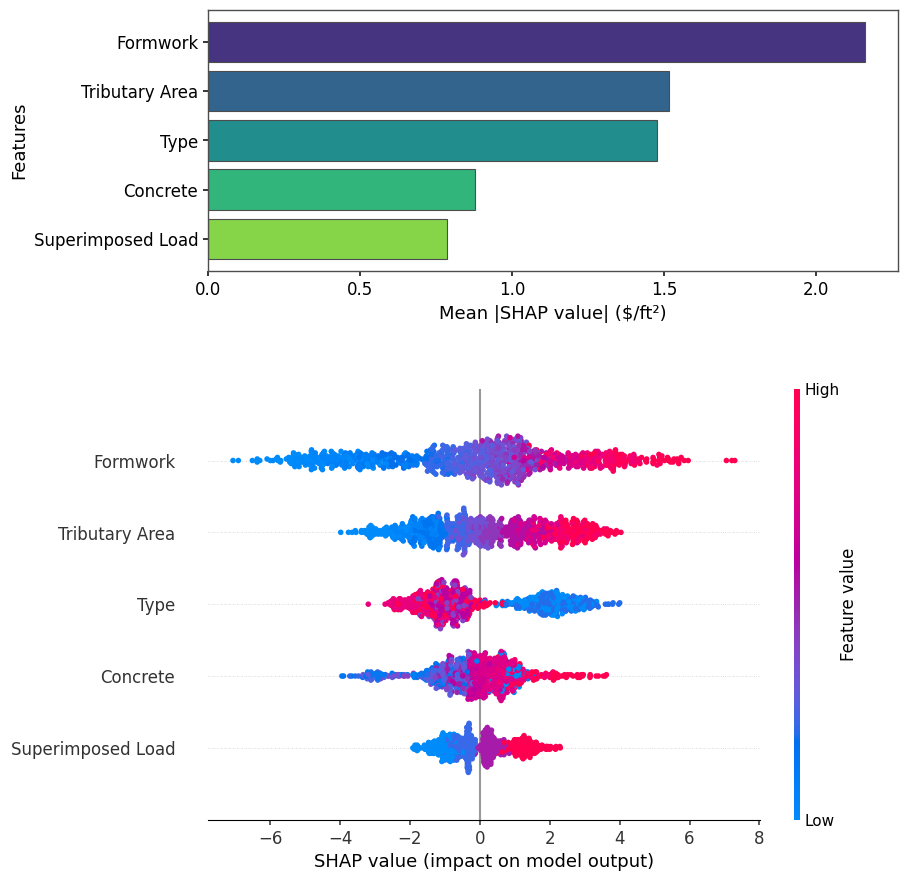

Combined SHAP figure saved to: /content/drive/MyDrive/AutoML/Round2_GroupedCV/figures/Figure6_FLAML_cross_fitted_SHAP.png


In [ ]:
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


shap_frames = []

for fold, (train_idx, test_idx) in enumerate(
    outer_splits,
    start=1,
):
    print(
        f"Computing cross-fitted SHAP values: "
        f"fold {fold}/{len(outer_splits)}"
    )

    model_path = (
        MODEL_DIR
        / f"FLAML_fold_{fold}.joblib"
    )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Run FLAML first: {model_path}"
        )


    automl = joblib.load(model_path)


    background = (
        data.iloc[train_idx][FEATURES]
        .sample(
            n=min(100, len(train_idx)),
            random_state=SEED + fold,
        )
    )


    explained = (
        data.iloc[test_idx][FEATURES]
        .sample(
            n=min(200, len(test_idx)),
            random_state=SEED + fold,
        )
    )


    explainer = shap.Explainer(
        automl.predict,
        background,
        algorithm="permutation",
    )

    explanation = explainer(
        explained,
        max_evals=2 * len(FEATURES) + 1,
    )

    fold_shap = pd.DataFrame(
        explanation.values,
        columns=FEATURES,
    )


    if "RowID" in data.columns:
        fold_shap["RowID"] = (
            data.loc[explained.index, "RowID"]
            .to_numpy()
        )
    else:
        fold_shap["RowID"] = (
            explained.index.to_numpy()
        )

    fold_shap["Fold"] = fold

    shap_frames.append(
        fold_shap
    )



cross_fitted_shap = pd.concat(
    shap_frames,
    ignore_index=True,
)

cross_fitted_shap.to_csv(
    TABLE_DIR
    / "FLAML_cross_fitted_SHAP_values.csv",
    index=False,
    encoding="utf-8-sig",
)

shap_values = (
    cross_fitted_shap[FEATURES]
    .to_numpy(dtype=float)
)


if "RowID" in data.columns:
    feature_data_by_row = (
        data
        .set_index("RowID")[FEATURES]
    )

    shap_rows = (
        feature_data_by_row
        .loc[
            cross_fitted_shap["RowID"],
            FEATURES,
        ]
        .copy()
    )
else:
    shap_rows = (
        data.loc[
            cross_fitted_shap["RowID"],
            FEATURES,
        ]
        .copy()
    )


shap_rows = shap_rows.reset_index(
    drop=True
)



mean_absolute_shap = np.mean(
    np.abs(shap_values),
    axis=0,
)

shap_importance = pd.DataFrame({
    "Feature": FEATURES,
    "MeanAbsoluteSHAP": mean_absolute_shap,
})

shap_importance = (
    shap_importance
    .sort_values(
        "MeanAbsoluteSHAP",
        ascending=False,
    )
    .reset_index(drop=True)
)

print(
    "\n=== Cross-fitted mean absolute "
    "SHAP importance ==="
)

display(shap_importance)

shap_importance.to_csv(
    TABLE_DIR
    / "FLAML_cross_fitted_SHAP_importance.csv",
    index=False,
    encoding="utf-8-sig",
)


figure = plt.figure(
    figsize=(10, 9)
)

grid = figure.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[1.0, 1.65],
    hspace=0.34,
)

bar_axis = figure.add_subplot(
    grid[0, 0]
)

beeswarm_axis = figure.add_subplot(
    grid[1, 0]
)



bar_features = (
    shap_importance["Feature"]
    .to_numpy()[::-1]
)

bar_values = (
    shap_importance["MeanAbsoluteSHAP"]
    .to_numpy()[::-1]
)


descending_colors = plt.cm.viridis(
    np.linspace(
        0.15,
        0.82,
        len(shap_importance),
    )
)

bar_colors = descending_colors[::-1]

bar_axis.barh(
    bar_features,
    bar_values,
    color=bar_colors,
    edgecolor="#4D4D4D",
    linewidth=0.8,
    height=0.82,
)

bar_axis.set_xlabel(
    "Mean |SHAP value| ($/ft²)",
    fontsize=13,
    fontweight="normal",
)

bar_axis.set_ylabel(
    "Features",
    fontsize=13,
    fontweight="normal",
)

bar_axis.tick_params(
    axis="both",
    labelsize=12,
    width=1.1,
)

bar_axis.grid(False)


maximum_importance = (
    shap_importance["MeanAbsoluteSHAP"]
    .max()
)

bar_axis.set_xlim(
    0,
    maximum_importance * 1.05,
)

for spine in bar_axis.spines.values():
    spine.set_edgecolor("#4D4D4D")
    spine.set_linewidth(1.0)



plt.sca(beeswarm_axis)

shap.summary_plot(
    shap_values,
    shap_rows,
    max_display=len(FEATURES),
    plot_type="dot",
    sort=True,
    show=False,
    plot_size=None,
    color_bar=True,
)

beeswarm_axis.set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=13,
    fontweight="normal",
)

beeswarm_axis.set_ylabel(
    "",
)

beeswarm_axis.tick_params(
    axis="both",
    labelsize=12,
    width=1.1,
)

beeswarm_axis.grid(
    axis="y",
    linestyle=":",
    linewidth=0.6,
    alpha=0.35,
)


if len(figure.axes) > 2:
    colorbar_axis = figure.axes[-1]

    colorbar_axis.tick_params(
        labelsize=11
    )

    colorbar_axis.set_ylabel(
        "Feature value",
        fontsize=12,
        fontweight="normal",
    )


figure.subplots_adjust(
    left=0.22,
    right=0.91,
    top=0.98,
    bottom=0.08,
    hspace=0.36,
)

figure_path = (
    FIGURE_DIR
    / "Figure6_FLAML_cross_fitted_SHAP.png"
)

figure.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print(
    "Combined SHAP figure saved to:",
    figure_path,
)

## 10. Consensus outlier audit and exclusion sensitivity



In [ ]:
wide_predictions = prediction_long.pivot(index="RowID", columns="Model", values="Predicted_Cost")
true_cost = prediction_long.groupby("RowID")["True_Cost"].first()
if prediction_long.groupby("RowID")["True_Cost"].nunique().max() != 1:
    raise ValueError("Models do not agree on True_Cost for one or more RowID values.")

errors = wide_predictions.sub(true_cost, axis=0)
median_prediction = wide_predictions.median(axis=1)
median_absolute_error = errors.abs().median(axis=1)
same_direction_fraction = errors.gt(0).mean(axis=1).where(
    errors.median(axis=1).ge(0), errors.lt(0).mean(axis=1)
)
high_error_threshold = median_absolute_error.quantile(0.95)

consensus_flag = (same_direction_fraction >= 0.80) & (median_absolute_error >= high_error_threshold)
reviewer_band_flag = true_cost.between(10, 14) & median_prediction.between(18, 25)
flagged_ids = wide_predictions.index[consensus_flag | reviewer_band_flag]

outlier_audit = data.set_index("RowID").loc[flagged_ids].copy()
outlier_audit["MedianPrediction"] = median_prediction.loc[flagged_ids]
outlier_audit["MedianAbsoluteError"] = median_absolute_error.loc[flagged_ids]
outlier_audit["SameDirectionModelFraction"] = same_direction_fraction.loc[flagged_ids]
outlier_audit["ConsensusHighErrorFlag"] = consensus_flag.loc[flagged_ids]
outlier_audit["ReviewerApproximateBandFlag"] = reviewer_band_flag.loc[flagged_ids]
outlier_audit = outlier_audit.join(wide_predictions.add_prefix("Pred_"))
outlier_audit["SourceVerificationStatus"] = "Requires comparison with original RSMeans source"
outlier_audit.reset_index().to_csv(AUDIT_DIR / "consensus_outlier_audit.csv", index=False, encoding="utf-8-sig")
display(outlier_audit)

sensitivity_rows = []
for model_name, model_frame in prediction_long.groupby("Model"):
    full = regression_metrics(model_frame["True_Cost"], model_frame["Predicted_Cost"])
    retained = model_frame[~model_frame["RowID"].isin(flagged_ids)]
    excluded = regression_metrics(retained["True_Cost"], retained["Predicted_Cost"])
    sensitivity_rows.append({
        "Model": model_name,
        "FlaggedRows": len(flagged_ids),
        **{f"Full_{key}": value for key, value in full.items()},
        **{f"FlaggedExcluded_{key}": value for key, value in excluded.items()},
    })
outlier_sensitivity = pd.DataFrame(sensitivity_rows)
display(outlier_sensitivity)
outlier_sensitivity.to_csv(TABLE_DIR / "outlier_exclusion_sensitivity_not_primary.csv", index=False, encoding="utf-8-sig")

,Type,Tributary Area,Superimposed Load,Formwork,Concrete,Total Cost,ConfigurationID,OuterFold,MedianPrediction,MedianAbsoluteError,...,Pred_AutoGluon,Pred_FLAML,Pred_GCN-GAT-MLP,Pred_H2O,Pred_LGBoost+NGBoost,Pred_NGBoost,Pred_Random Forest,Pred_TPOT,Pred_XGBoost,SourceVerificationStatus
RowID,,,,,,,,,,,,,,,,,,,,,
160,1,225,40,4.821029,2.631579,11.89,0,4,10.765997,1.124003,...,10.668694,10.115860,9.901865,9.933348,10.771212,10.760782,10.954800,11.269605,11.161044,Requires comparison with original RSMeans source
219,1,625,200,4.966443,2.768879,15.70,19,5,14.833908,0.866092,...,14.974745,15.368970,14.915399,14.823618,14.660730,14.093586,14.512211,14.577044,14.844199,Requires comparison with original RSMeans source
258,1,625,125,5.648770,3.089245,16.40,18,1,15.532890,0.867110,...,16.036976,16.185480,15.308197,15.863926,14.879478,14.403472,15.494083,15.287883,15.571696,Requires comparison with original RSMeans source
259,1,625,200,5.648770,3.089245,17.70,19,5,16.627021,1.072979,...,16.888283,17.076017,16.731152,16.728869,15.740115,15.212491,16.281922,15.815116,16.525173,Requires comparison with original RSMeans source
260,1,750,40,5.648770,3.089245,13.41,20,4,14.231817,0.821817,...,13.960275,13.983827,13.642555,14.311510,14.458045,14.152124,14.594367,16.671876,14.441123,Requires comparison with original RSMeans source
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4394,6,1400,200,11.520000,5.072464,27.05,210,2,25.507459,1.542541,...,25.137827,26.021184,26.263718,26.051118,25.728900,25.286017,25.258273,25.232242,25.089212,Requires comparison with original RSMeans source
4432,6,1400,200,13.400000,5.188406,29.05,210,2,27.300511,1.749489,...,26.996569,27.943927,27.774174,27.919132,27.293493,27.194591,27.298636,27.302385,27.062401,Requires comparison with original RSMeans source
4462,6,1050,200,13.750000,5.217391,27.80,202,5,26.766003,1.033997,...,26.540691,27.261589,26.991314,27.330759,27.224377,26.287658,26.516111,24.042515,26.280758,Requires comparison with original RSMeans source


,Model,FlaggedRows,Full_RMSE,Full_MAE,Full_MAPE_percent,FlaggedExcluded_RMSE,FlaggedExcluded_MAE,FlaggedExcluded_MAPE_percent
0,ANN,220,0.568871,0.360957,2.233990,0.428816,0.328457,2.039877
1,AutoGluon,220,0.566799,0.355796,2.153258,0.398197,0.306364,1.883600
2,FLAML,220,0.495440,0.304931,1.877974,0.346139,0.272911,1.691131
3,GCN-GAT-MLP,220,0.632952,0.420855,2.614607,0.480521,0.377102,2.372806
4,H2O,220,0.499579,0.301435,1.901140,0.335501,0.264474,1.692263
5,LGBoost+NGBoost,220,0.617409,0.412385,2.541791,0.449895,0.359294,2.258651
6,NGBoost,220,0.895269,0.642697,3.949241,0.746300,0.577024,3.627040
7,Random Forest,220,0.642616,0.416322,2.484602,0.473308,0.360512,2.188055
8,TPOT,220,0.897107,0.631924,3.888711,0.766402,0.573109,3.600752
9,XGBoost,220,0.636379,0.437978,2.753805,0.474590,0.384435,2.481963
